# Modul 4 — Menghilangkan Duplikat dan Perbaikan Format Data

**Praktikum Data Wrangling (SD25-20007) · Program Studi Sains Data ITERA**

Workbench menyimpan notebook ini di laptop sebagai **`dw-module-04/04_duplikat.ipynb`**; seluruh
keluaran modul ditulis ke folder `dw-module-04/` itu. Modul ini membaca keluaran Modul 3 Anda
sendiri dari **`dw-module-03/keluaran/transaksi_m03.parquet`**, serta `produk.csv`,
`pelanggan_web.csv`, dan `pelanggan_app.csv` mentah. Dataset mentah disiapkan lewat panel
*Dataset di laptop* halaman modul (Local Runner menyala). Buku ajar: Bab 2.2.4–2.2.5,
3.4.4–3.4.5, dan Bab 5.

| Bagian | Isi notebook ini | Dinilai? |
|---|---|---|
| A–D Prosedur terbimbing | **kode lengkap dan pembahasan** | dijalankan dan lulus checkpoint |
| Latihan 4.1–4.2 | kerangka `TODO` | **ya** — *Latihan Mandiri di Lab* (20% nilai modul) |
| Tugas Individu | kerangka `TODO` | **ya** — *Tugas Individu* (80% nilai modul) |

Bagian A–D bukan untuk disalin tanpa dibaca. Latihan dan tugas memakai **cara berpikir yang
sama** pada data lain (tanggal daftar pelanggan, katalog produk dan toko, resolusi entitas
tanpa nomor HP), dan pertanyaan analisis menanyakan alasan di balik setiap langkah A–D.

**Aturan main**
1. `data/raw/` dan keluaran Modul 3 bersifat *read-only* — jangan menulis ke sana.
2. Penyeragaman format memakai tabel pemetaan tercatat; nilai yang belum terpetakan menghentikan notebook.
3. Baris hanya dibuang bila terbukti duplikat, dan setiap baris yang dibuang tercatat pada tabel duplikat.
4. Nilai asli disimpan pada kolom `<kolom>_asli`; setiap keputusan dicatat pada `log-keputusan.csv` di akar workspace.
5. Sebelum mengumpulkan: *Kernel → Restart Kernel and Run All Cells*, lalu jalankan Checkpoint.

## Bagian A — Standardisasi format dengan tabel pemetaan tercatat

### A.1 Menyiapkan notebook

In [1]:
import shutil
import sys
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib

# Kernel DSWorkbench menjalankan sel di luar thread utama, sehingga backend GUI
# (mis. "macosx") gagal membuat figure. Di luar Jupyter/ipykernel dipakai Agg;
# figure yang terbuka tetap ditampilkan kernel sebagai gambar di bawah sel.
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
    warnings.filterwarnings("ignore", message=r"FigureCanvas\w* is non-interactive")
import matplotlib.pyplot as plt
from rapidfuzz import fuzz, process
from rapidfuzz.distance import JaroWinkler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data" / "raw").is_dir())
RAW = ROOT / "data" / "raw"
M03 = ROOT / "dw-module-03" / "keluaran"   # keluaran Modul 3 milik Anda sendiri
MODUL = ROOT / "dw-module-04"      # folder tempat Workbench menyimpan notebook ini
LOG = ROOT / "log-keputusan.csv"
OUT = MODUL / "keluaran"
OUT.mkdir(parents=True, exist_ok=True)
SEED = 2026
pd.set_option("display.width", 140)

if not (M03 / "transaksi_m03.parquet").exists():
    raise FileNotFoundError(f"Belum ada di {M03}: transaksi_m03.parquet. "
                            "Selesaikan dan jalankan ulang notebook Modul 3 lebih dulu.")
t3 = pd.read_parquet(M03 / "transaksi_m03.parquet")
baca = lambda nama: pd.read_csv(RAW / nama, dtype=str, keep_default_na=False)  # noqa: E731
mentah, produk = baca("transaksi.csv"), baca("produk.csv")
web, app = baca("pelanggan_web.csv"), baca("pelanggan_app.csv")
assert len(t3) == len(mentah) and t3.id_pesanan.astype(str).equals(mentah.id_pesanan), \
    "transaksi_m03 tidak sejajar dengan data mentah; periksa ulang Modul 3"
t3["baris_m03"] = np.arange(len(t3))      # posisi baris Modul 3: jejak setiap baris sampai Modul 9
print("Akar repositori :", ROOT.name)
print("transaksi_m03   :", t3.shape, "| produk:", produk.shape, "| web:", web.shape, "| app:", app.shape)

Akar repositori : data-wrangling
transaksi_m03   : (24288, 31) | produk: (850, 10) | web: (3260, 9) | app: (2600, 8)


In [2]:
def rp(x: float) -> str:
    """Rupiah berformat Indonesia untuk teks bukti: 1234567 -> 'Rp1.234.567'."""
    return f"Rp{x:,.0f}".replace(",", ".")


def angka(x: float, d: int = 1) -> str:
    """Angka berformat Indonesia untuk teks bukti: 90.66 -> '90,7'."""
    return f"{x:,.{d}f}".replace(",", "_").replace(".", ",").replace("_", ".")


def kunci_teks(x: str) -> str:
    """Bentuk pembanding: huruf kecil (casefold) dan spasi dirapatkan. BUKAN nilai kanonik."""
    return " ".join(str(x).casefold().split())


B: dict = {}       # angka bukti yang dipakai ulang pada tabel, log, dan pembahasan

### A.2 Tabel pemetaan: status dan metode bayar

In [3]:
PETA: list[dict] = []          # seluruh pemetaan format -> keluaran/peta_format_m04.csv


def jenis_beda(asli: str, kanonik: str) -> str:
    """Seberapa jauh penulisan asli dari bentuk kanoniknya."""
    if pd.isna(kanonik):
        return "kosong"
    if asli == kanonik:
        return "identik"
    return "huruf_spasi" if kunci_teks(asli) == kunci_teks(kanonik) else "pengetahuan_domain"


def petakan(nilai: pd.Series, peta: dict, kolom: str) -> pd.Series:
    """Terapkan tabel pemetaan nilai_asli -> nilai_kanonik dan catat setiap pasangannya.
    Berhenti bila ada nilai yang belum terpetakan: tidak ada nilai yang lolos diam-diam."""
    belum = sorted(set(nilai.dropna().unique()) - set(peta))
    if belum:
        raise KeyError(f"{kolom}: {len(belum)} nilai belum terpetakan, misalnya {belum[:8]}")
    n = nilai.value_counts()
    PETA[:] = [p for p in PETA if p["kolom"] != kolom]       # aman dijalankan ulang
    PETA.extend({"kolom": kolom, "nilai_asli": a, "nilai_kanonik": k, "aturan": jenis_beda(a, k),
                 "n_baris": int(n[a])} for a, k in peta.items() if a in n.index)
    return nilai.map(peta)


peta_status = {s: s.lower() for s in t3.status.unique()}
status_baru = petakan(t3.status, peta_status, "transaksi.status")

KATEGORI_BAYAR = ["E-Wallet", "Transfer Bank", "COD", "Kartu Kredit", "Paylater"]
peta_bayar = {v: k for v in t3.metode_bayar.unique() for k in KATEGORI_BAYAR
              if kunci_teks(v) == kunci_teks(k)}
print("status:", t3.status.nunique(), "penulisan ->", sorted(status_baru.unique()))
print("metode bayar:", t3.metode_bayar.nunique(), "penulisan;", len(peta_bayar),
      "terpetakan otomatis; sisa:", sorted(set(t3.metode_bayar) - set(peta_bayar)))

status: 8 penulisan -> ['dibatalkan', 'dikembalikan', 'diproses', 'selesai']
metode bayar: 16 penulisan; 10 terpetakan otomatis; sisa: ['Bayar di Tempat', 'CC', 'EWALLET', 'GoPay', 'OVO', 'transfer']


In [4]:
peta_bayar |= {"EWALLET": "E-Wallet", "OVO": "E-Wallet", "GoPay": "E-Wallet",     # merek dompet digital
               "transfer": "Transfer Bank", "Bayar di Tempat": "COD", "CC": "Kartu Kredit"}
bayar_baru = petakan(t3.metode_bayar, peta_bayar, "transaksi.metode_bayar")

# uji: idempoten (Bab 5.4: phi(phi(s)) = phi(s)) dan banyak kategori kanonik
assert status_baru.map(peta_status).equals(status_baru)
assert bayar_baru.map(peta_bayar).equals(bayar_baru)
assert sorted(bayar_baru.unique()) == sorted(KATEGORI_BAYAR)
B["status_varian"], B["status_kapital"] = t3.status.nunique(), int(t3.status.ne(status_baru).sum())
B["bayar_varian"], B["bayar_berubah"] = t3.metode_bayar.nunique(), int(t3.metode_bayar.ne(bayar_baru).sum())
B["bayar_merek"] = int(t3.metode_bayar.isin(["OVO", "GoPay"]).sum())
aturan_bayar = pd.Series({a: jenis_beda(a, k) for a, k in peta_bayar.items()}).value_counts()
print(f"status: {B['status_varian']} penulisan, {B['status_kapital']} baris kapital")
print(f"metode bayar: {B['bayar_varian']} penulisan -> 5; {B['bayar_berubah']} baris berubah penulisan;",
      f"merek OVO/GoPay {B['bayar_merek']} baris")
print("jenis beda penulisan:", aturan_bayar.to_dict())
bayar_baru.value_counts()

status: 8 penulisan, 466 baris kapital
metode bayar: 16 penulisan -> 5; 17265 baris berubah penulisan; merek OVO/GoPay 4180 baris
jenis beda penulisan: {'pengetahuan_domain': 6, 'identik': 5, 'huruf_spasi': 5}


metode_bayar
E-Wallet         10255
Transfer Bank     6135
COD               4365
Paylater          1920
Kartu Kredit      1613
Name: count, dtype: int64

### A.3 Wilayah: kota dan provinsi

In [5]:
KOTA_LAYANAN = {   # kota tujuan kanonik -> provinsinya (daftar operasional Lapak Sumatera)
    "Banda Aceh": "Aceh", "Medan": "Sumatera Utara", "Padang": "Sumatera Barat",
    "Pekanbaru": "Riau", "Jambi": "Jambi", "Palembang": "Sumatera Selatan",
    "Bengkulu": "Bengkulu", "Bandar Lampung": "Lampung",
    "Pangkalpinang": "Kepulauan Bangka Belitung", "Batam": "Kepulauan Riau"}
PROVINSI = sorted(set(KOTA_LAYANAN.values()))


def kunci_wilayah(x: str) -> str:
    """Pembanding wilayah: huruf kecil, tanpa awalan 'kota', tanpa spasi dan tanda baca."""
    x = kunci_teks(x).removeprefix("kota ")
    return "".join(c for c in x if c.isalnum())


def usul_wilayah(nilai: pd.Series, kanonik: list[str]) -> dict:
    """Usulan pemetaan otomatis: hanya penulisan yang kunci_wilayah-nya sama persis."""
    acuan = {kunci_wilayah(k): k for k in kanonik}
    return {v: acuan[kunci_wilayah(v)] for v in nilai.unique() if kunci_wilayah(v) in acuan}


semua_kota = pd.concat([t3.kota_tujuan, web.kota, app.city])
semua_prov = pd.concat([t3.provinsi_tujuan, web.provinsi])
peta_kota = usul_wilayah(semua_kota, list(KOTA_LAYANAN))
peta_prov = usul_wilayah(semua_prov, PROVINSI)
for nama, semua, peta in [("kota", semua_kota, peta_kota), ("provinsi", semua_prov, peta_prov)]:
    print(f"{nama}: {semua.nunique()} penulisan, {len(peta)} terpetakan otomatis, "
          f"sisa {sorted(set(semua) - set(peta))}")

kota: 28 penulisan, 26 terpetakan otomatis, sisa ['B. Lampung', 'Plg']
provinsi: 20 penulisan, 13 terpetakan otomatis, sisa ['Babel', 'Kepri', 'NAD', 'Sumatra Utara', 'Sumbar', 'Sumsel', 'Sumut']


In [6]:
sisa_kota = sorted(set(semua_kota) - set(peta_kota))
sisa_prov = sorted(set(semua_prov) - set(peta_prov))
peta_kota |= {"Plg": "Palembang", "B. Lampung": "Bandar Lampung"}
peta_prov |= {"NAD": "Aceh", "Sumut": "Sumatera Utara", "Sumatra Utara": "Sumatera Utara",
              "Sumbar": "Sumatera Barat", "Sumsel": "Sumatera Selatan",
              "Babel": "Kepulauan Bangka Belitung", "Kepri": "Kepulauan Riau"}
# usulan kemiripan string untuk penulisan yang tidak terpetakan otomatis
usul = pd.DataFrame(
    [{"nilai_asli": v, "usul_rapidfuzz": process.extractOne(v, acuan, scorer=fuzz.WRatio)[0],
      "skor": round(process.extractOne(v, acuan, scorer=fuzz.WRatio)[1], 1), "benar": peta[v]}
     for sisa, acuan, peta in [(sisa_kota, list(KOTA_LAYANAN), peta_kota), (sisa_prov, PROVINSI, peta_prov)]
     for v in sisa])
usul["tepat"] = usul.usul_rapidfuzz.eq(usul.benar)
B["fuzzy_sisa"], B["fuzzy_salah"] = len(usul), int((~usul.tepat).sum())
print(usul.to_string(index=False))

kota_baru = petakan(t3.kota_tujuan, peta_kota, "transaksi.kota_tujuan")
prov_baru = petakan(t3.provinsi_tujuan, peta_prov, "transaksi.provinsi_tujuan")
web_kota = petakan(web.kota, peta_kota, "pelanggan_web.kota")
web_prov = petakan(web.provinsi, peta_prov, "pelanggan_web.provinsi")
app_kota = petakan(app.city, peta_kota, "pelanggan_app.city")
B["transaksi_tak_konsisten"] = int(kota_baru.map(KOTA_LAYANAN).ne(prov_baru).sum())
B["web_tak_konsisten"] = int(web_kota.map(KOTA_LAYANAN).ne(web_prov).sum())
B["kota_varian"], B["prov_varian"] = t3.kota_tujuan.nunique(), t3.provinsi_tujuan.nunique()
B["kota_berubah"] = int(t3.kota_tujuan.ne(kota_baru).sum())
B["prov_berubah"] = int(t3.provinsi_tujuan.ne(prov_baru).sum())


def aturan_wilayah(asli: str, kanonik: str) -> str:
    j = jenis_beda(asli, kanonik)
    if j == "pengetahuan_domain" and kunci_wilayah(asli) == kunci_wilayah(kanonik):
        return "awalan_atau_spasi"
    return "singkatan_atau_ejaan" if j == "pengetahuan_domain" else j


baris_peta = []
for jenis, peta, kolom in [("kota", peta_kota, {"n_transaksi": t3.kota_tujuan, "n_web": web.kota, "n_app": app.city}),
                           ("provinsi", peta_prov, {"n_transaksi": t3.provinsi_tujuan, "n_web": web.provinsi})]:
    for asli, kanonik in sorted(peta.items()):
        r = {"jenis": jenis, "nilai_asli": asli, "nilai_kanonik": kanonik,
             "provinsi": KOTA_LAYANAN[kanonik] if jenis == "kota" else kanonik,
             "aturan": aturan_wilayah(asli, kanonik)}
        r |= {k: int(s.eq(asli).sum()) for k, s in kolom.items()}
        baris_peta.append(r)
peta_wilayah = pd.DataFrame(baris_peta, columns=["jenis", "nilai_asli", "nilai_kanonik", "provinsi", "aturan",
                                                 "n_transaksi", "n_web", "n_app"]).fillna({"n_app": 0})
peta_wilayah["n_app"] = peta_wilayah.n_app.astype(int)
peta_wilayah.to_csv(OUT / "peta_wilayah_m04.csv", index=False)
print(f"\nkota {B['kota_varian']} penulisan -> {kota_baru.nunique()}; provinsi {B['prov_varian']} -> {prov_baru.nunique()};",
      f"kota-provinsi tidak konsisten: transaksi {B['transaksi_tak_konsisten']}, web {B['web_tak_konsisten']}")
peta_wilayah.groupby(["jenis", "aturan"]).size().unstack(fill_value=0)

   nilai_asli            usul_rapidfuzz  skor                     benar  tepat
   B. Lampung            Bandar Lampung  78.2            Bandar Lampung   True
          Plg                 Palembang  60.0                 Palembang   True
        Babel Kepulauan Bangka Belitung  54.0 Kepulauan Bangka Belitung   True
        Kepri Kepulauan Bangka Belitung  67.5            Kepulauan Riau  False
          NAD                      Aceh  28.6                      Aceh   True
Sumatra Utara            Sumatera Utara  96.3            Sumatera Utara   True
       Sumbar            Sumatera Barat  72.0            Sumatera Barat   True
       Sumsel            Sumatera Barat  60.0          Sumatera Selatan  False
        Sumut            Sumatera Barat  72.0            Sumatera Utara  False

kota 28 penulisan -> 10; provinsi 20 -> 10; kota-provinsi tidak konsisten: transaksi 0, web 0


aturan,awalan_atau_spasi,huruf_spasi,identik,singkatan_atau_ejaan
jenis,,,,
kota,9,7,10,2
provinsi,0,3,10,7


### A.4 Waktu: tiga format dan zona waktu

In [7]:
FORMAT_WAKTU = {"iso_wib": "%Y-%m-%d %H:%M:%S",     # web
                "dmy_wib": "%d/%m/%Y %H:%M",        # web, tanpa detik
                "iso_utc": "%Y-%m-%dT%H:%M:%SZ"}    # aplikasi, UTC


def urai_waktu(teks: pd.Series) -> tuple[pd.Series, pd.Series]:
    """Urai waktu_pesan dengan format eksplisit; UTC dikonversi ke Asia/Jakarta lalu dibuat naif.
    Mengembalikan (waktu WIB, nama format). Berhenti bila ada teks yang tidak cocok."""
    waktu = pd.Series(pd.NaT, index=teks.index, dtype="datetime64[us]")
    nama = pd.Series(pd.NA, index=teks.index, dtype="str")
    for f, pola in FORMAT_WAKTU.items():
        w = pd.to_datetime(teks, format=pola, errors="coerce")
        if f == "iso_utc":
            w = w.dt.tz_localize("UTC").dt.tz_convert("Asia/Jakarta").dt.tz_localize(None)
        isi = w.notna() & waktu.isna()
        waktu[isi], nama[isi] = w[isi], f
    if nama.isna().any():
        raise ValueError(f"{int(nama.isna().sum())} waktu tidak cocok dengan format mana pun: "
                         f"{teks[nama.isna()].unique()[:5]}")
    return waktu, nama


waktu_wib, format_waktu = urai_waktu(t3.waktu_pesan)
pd.crosstab(format_waktu, t3.kanal)

kanal,app,web
row_0,,
dmy_wib,0,1957
iso_utc,11114,0
iso_wib,0,11217


format='mixed' seluruh kolom: Mixed timezones detected; hanya baris web: tanpa galat, tetapi 706 dari 1957 waktu berpola dd/mm berbeda dari parser eksplisit
di luar masa operasi: 18 {'1970': 13, '2062': 5}
pesanan aplikasi berganti tanggal 3243 dari 11111 (29,2%), berganti bulan 102
selisih UTC->WIB selalu tepat 7 jam: True


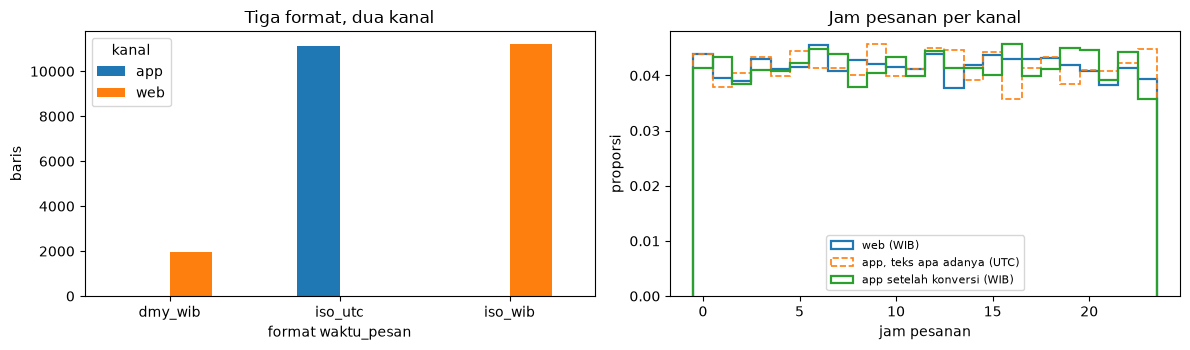

In [8]:
AWAL, AKHIR = pd.Timestamp("2025-01-01"), pd.Timestamp("2026-06-30 23:59:59")   # masa operasi
di_luar = ~waktu_wib.between(AWAL, AKHIR)
waktu_bersih = waktu_wib.mask(di_luar)
waktu_status = pd.Series(np.where(di_luar, "di_luar_rentang", "valid"), index=t3.index)
B["waktu_luar"] = int(di_luar.sum())
B["waktu_luar_tahun"] = t3.waktu_pesan[di_luar].str.extract(r"(19\d\d|20\d\d)")[0].value_counts().to_dict()
dari_app = format_waktu.eq("iso_utc")
teks_utc = pd.to_datetime(t3.waktu_pesan.where(dari_app), format=FORMAT_WAKTU["iso_utc"], errors="coerce")
sah_app = dari_app & ~di_luar
B["app_ganti_tanggal"] = int((sah_app & teks_utc.dt.normalize().ne(waktu_bersih.dt.normalize())).sum())
B["app_ganti_bulan"] = int((sah_app & teks_utc.dt.to_period("M").ne(waktu_bersih.dt.to_period("M"))).sum())
B["app_sah"] = int(sah_app.sum())
B["selisih_tetap_7jam"] = bool((waktu_wib[dari_app] - teks_utc[dari_app]).eq(pd.Timedelta(hours=7)).all())
# jalan pintas format="mixed": gagal pada seluruh kolom, diam-diam salah pada baris web
try:
    pd.to_datetime(t3.waktu_pesan, format="mixed")
    B["mixed_semua"] = "tidak gagal"
except ValueError as e:
    B["mixed_semua"] = str(e).split(".")[0]
mixed_web = pd.to_datetime(t3.waktu_pesan[~dari_app], format="mixed")
B["mixed_web_beda"] = int(mixed_web.ne(waktu_wib[~dari_app]).sum())
B["dmy_n"] = int(format_waktu.eq("dmy_wib").sum())
print(f"format='mixed' seluruh kolom: {B['mixed_semua']}; hanya baris web: tanpa galat, tetapi "
      f"{B['mixed_web_beda']} dari {B['dmy_n']} waktu berpola dd/mm berbeda dari parser eksplisit")
print("di luar masa operasi:", B["waktu_luar"], B["waktu_luar_tahun"])
print(f"pesanan aplikasi berganti tanggal {B['app_ganti_tanggal']} dari {B['app_sah']} "
      f"({angka(100 * B['app_ganti_tanggal'] / B['app_sah'])}%), berganti bulan {B['app_ganti_bulan']}")
print("selisih UTC->WIB selalu tepat 7 jam:", B["selisih_tetap_7jam"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))
pd.crosstab(format_waktu, t3.kanal).plot.bar(ax=ax1, rot=0)
ax1.set_ylabel("baris"); ax1.set_xlabel("format waktu_pesan"); ax1.set_title("Tiga format, dua kanal")
jam = np.arange(25) - .5
ax2.hist(waktu_bersih[t3.kanal.eq("web")].dt.hour, bins=jam, histtype="step", lw=1.6, label="web (WIB)", density=True)
ax2.hist(teks_utc[sah_app].dt.hour, bins=jam, histtype="step", lw=1.2, ls="--", label="app, teks apa adanya (UTC)", density=True)
ax2.hist(waktu_bersih[sah_app].dt.hour, bins=jam, histtype="step", lw=1.6, label="app setelah konversi (WIB)", density=True)
ax2.set_xlabel("jam pesanan"); ax2.set_ylabel("proporsi"); ax2.legend(fontsize=8); ax2.set_title("Jam pesanan per kanal")
fig.tight_layout(); fig.savefig(OUT / "01_waktu_format.png", dpi=110, bbox_inches="tight"); plt.show()

### A.5 Angka dan katalog produk

In [9]:
diskon_asli = pd.to_numeric(t3.diskon_persen)
print(pd.crosstab(diskon_asli, t3.kanal).T.to_string())


def rupiah(teks: pd.Series) -> pd.Series:
    """Dari Modul 3, kini keputusan permanen: 'Rp1.330.500', '1.330.500,00', 'Rp 79.000', '74500'."""
    bersih = (teks.str.replace("Rp", "", regex=False).str.strip()
                  .str.replace(r",00$", "", regex=True).str.replace(".", "", regex=False))
    return pd.to_numeric(bersih, errors="raise").astype("int64")


print(produk.berat.str.replace(r"\d+", "9", regex=True).value_counts().to_string())
produk.kategori.value_counts()

diskon_persen  0.00   0.05   0.10   0.15   0.20   0.25   5.00   10.00  15.00  20.00  25.00
kanal                                                                                     
app             4202    110    100     91    103    111   1262   1305   1267   1278   1285
web             4913      0      0      0      0      0   1664   1668   1678   1616   1635
berat
9 g       368
9,9 kg    162
9.9kg     158
9gr       158
9kg         3
9 kg        1


kategori
Kopi                    157
Makanan Ringan          152
Rempah                  128
Olahan Ikan             113
Kerajinan               112
Sayur dan Buah Segar    104
Kain Tenun               57
MAKANAN RINGAN            4
Kopi                      3
makanan ringan            3
REMPAH                    2
Kain Tenun                2
SAYUR DAN BUAH SEGAR      2
Rempah                    2
OLAHAN IKAN               1
kopi                      1
Olahan Ikan               1
KERAJINAN                 1
KAIN TENUN                1
KOPI                      1
sayur dan buah segar      1
olahan ikan               1
kerajinan                 1
Name: count, dtype: int64

In [10]:
pecahan = diskon_asli.gt(0) & diskon_asli.lt(1)
diskon_baru = diskon_asli.where(~pecahan, (diskon_asli * 100).round(6))
diskon_metode = pd.Series(np.where(pecahan, "pecahan_dikali_100", "teramati"), index=t3.index)
assert set(diskon_baru.unique()) <= {0, 5, 10, 15, 20, 25}
B["diskon_pecahan"] = int(pecahan.sum())
B["diskon_pecahan_kanal"] = t3.kanal[pecahan].value_counts().to_dict()


def gram(teks: pd.Series) -> pd.Series:
    """'250 g', '250gr', '0,25 kg', '0.25kg' -> 250. Koma DAN titik di sini pemisah desimal."""
    t = teks.str.strip().str.casefold()
    kg = t.str.endswith("kg")
    nilai = pd.to_numeric(t.str.replace(r"\s*(kg|gr|g)$", "", regex=True).str.replace(",", ".", regex=False),
                          errors="raise") * np.where(kg, 1000, 1)
    assert np.allclose(nilai, nilai.round()), "berat bukan gram bulat"
    return nilai.round().astype("int64")


berat_gram = gram(produk.berat)
naif = pd.to_numeric(produk.berat.str.extract(r"^([\d.,]+)")[0].str.replace(".", "", regex=False)
                     .str.replace(",", ".", regex=False)) * np.where(produk.berat.str.contains("kg"), 1000, 1)
B["berat_titik"] = int(produk.berat.str.contains(r"\d\.\d").sum())
B["berat_naif_salah"] = int(naif.ne(berat_gram).sum())
B["berat_naif_contoh"] = produk.berat[naif.ne(berat_gram)].iloc[0], float(naif[naif.ne(berat_gram)].iloc[0])

kelompok = produk.kategori.map(kunci_teks)
ejaan = produk.groupby(kelompok).kategori.agg(lambda s: s.value_counts().idxmax())   # ejaan terbanyak
peta_kategori = {v: ejaan[kunci_teks(v)] for v in produk.kategori.unique()}
kategori_baru = petakan(produk.kategori, peta_kategori, "produk.kategori")
assert kategori_baru.map(peta_kategori).equals(kategori_baru)
# saksi kategori: tiga huruf pada kode produk (LS-KOP-0001 -> Kopi)
B["kategori_prefix_cocok"] = bool(produk.kode_produk.str[3:6].eq(kategori_baru.str[:3].str.upper()).all())
B["kategori_varian"], B["kategori_kanonik"] = produk.kategori.nunique(), kategori_baru.nunique()
B["kategori_berubah"] = int(produk.kategori.ne(kategori_baru).sum())
B["title_salah"] = int(produk.kategori.str.strip().str.title().ne(kategori_baru).sum())

peta_dingin = {"Ya": True, "Y": True, "1": True, "Tidak": False, "T": False, "0": False}
dingin = petakan(produk.perlu_pendingin, peta_dingin, "produk.perlu_pendingin").astype(bool)
B["dingin_per_kategori"] = dingin.groupby(kategori_baru).mean().round(2).to_dict()
rating = pd.to_numeric(produk.rating_toko)
penanda = rating.eq(0)
B["rating_penanda"] = int(penanda.sum())

produk_m04 = pd.DataFrame({
    "kode_produk": produk.kode_produk, "nama_produk": produk.nama_produk,
    "id_toko": produk.id_toko, "nama_toko": produk.nama_toko, "kategori": kategori_baru,
    "harga_katalog_rp": rupiah(produk.harga_katalog), "berat_gram": berat_gram,
    "provinsi_toko": produk.provinsi_toko, "perlu_pendingin": dingin,
    "rating_toko": rating.mask(penanda).astype("float64"),
    "rating_toko_status": np.where(penanda, "penanda", "teramati"),
    "kategori_asli": produk.kategori, "harga_katalog_asli": produk.harga_katalog,
    "berat_asli": produk.berat, "perlu_pendingin_asli": produk.perlu_pendingin})
assert produk_m04.kode_produk.is_unique and set(produk_m04.provinsi_toko) <= set(PROVINSI)
produk_m04.to_parquet(OUT / "produk_m04.parquet", index=False)
print(f"diskon pecahan: {B['diskon_pecahan']} baris {B['diskon_pecahan_kanal']}")
print(f"berat: {B['berat_titik']} bertitik desimal; cara naif salah pada {B['berat_naif_salah']} produk, "
      f"misalnya {B['berat_naif_contoh']}")
print(f"kategori: {B['kategori_varian']} penulisan -> {B['kategori_kanonik']}; cocok dengan kode: "
      f"{B['kategori_prefix_cocok']}; str.title() salah pada {B['title_salah']} produk")
print("perlu pendingin per kategori:", B["dingin_per_kategori"])
print("rating toko 0,0 (penanda):", B["rating_penanda"], "| produk_m04:", produk_m04.shape)

diskon pecahan: 515 baris {'app': 515}
berat: 158 bertitik desimal; cara naif salah pada 158 produk, misalnya ('0.95kg', 95000.0)
kategori: 23 penulisan -> 7; cocok dengan kode: True; str.title() salah pada 107 produk
perlu pendingin per kategori: {'Kain Tenun': 0.0, 'Kerajinan': 0.0, 'Kopi': 0.0, 'Makanan Ringan': 0.0, 'Olahan Ikan': 1.0, 'Rempah': 0.0, 'Sayur dan Buah Segar': 1.0}
rating toko 0,0 (penanda): 61 | produk_m04: (850, 15)


**Pembahasan A**

| Kolom | Penulisan asli | Kanonik | Baris berubah | Catatan |
|---|---:|---:|---:|---|
| `status` | 8 | 4 | 466 | huruf kapital (A-13); cukup `lower()` |
| `metode_bayar` | 16 | 5 | 17.265 | 6 penulisan butuh pengetahuan domain: merek **OVO, GoPay** (4.180 baris) adalah dompet digital, `CC` kartu kredit, `Bayar di Tempat` COD (A-15) |
| `kota_tujuan` | 28 | 10 | 15.941 | awalan "Kota", spasi di ujung (`MEDAN `), "Pekan Baru"; `Plg` dan `B. Lampung` singkatan (A-14) |
| `provinsi_tujuan` | 20 | 10 | 12.029 | `NAD`, `Sumut`, `Sumbar`, `Sumsel`, `Babel`, `Kepri`, ejaan `Sumatra Utara` |
| `waktu_pesan` | 3 format | `waktu_wib` | 11.114 dikonversi | aplikasi UTC (A-12); 18 di luar masa operasi → `NaT` (A-11) |
| `diskon_persen` | pecahan | persen | 515 | seluruhnya kanal aplikasi (A-07) |
| `produk.kategori` | 23 | 7 | 27 | huruf kapital dan spasi ujung (A-18) |

- **Kemiripan string tidak mengenal singkatan.** Dari 9 penulisan wilayah yang tidak terpetakan
  otomatis, usulan `process.extractOne(..., scorer=fuzz.WRatio)` **salah pada 3**: `Sumut` dan
  `Sumsel` diusulkan menjadi *Sumatera Barat*, dan `Kepri` menjadi *Kepulauan Bangka Belitung*.
  Enam lainnya benar, tetapi skornya tidak membedakan yang benar dari yang salah: `Sumbar`
  (benar) dan `Sumut` (salah) sama-sama 72,0, sedangkan `NAD` → *Aceh* benar dengan skor 28,6.
  Skor tidak dapat dipakai sebagai ambang penerimaan; pemetaan diputuskan dengan pengetahuan
  domain lalu dicatat (Rattenbury dkk., 2017, Bab 7).
- Setelah dipetakan, kota dan provinsi **konsisten pada setiap baris** (0 baris dengan kota di luar
  provinsinya, transaksi maupun pelanggan web). `KOTA_LAYANAN` sekaligus memberi provinsi untuk
  pelanggan aplikasi yang tidak mencatat provinsi.
- **Waktu.** Satu panggilan `pd.to_datetime(..., format="mixed")` gagal karena zona waktu
  bercampur (`Mixed timezones detected`); versi yang hanya mengurai baris web tidak gagal tetapi
  **diam-diam** membaca 706 dari 1.957 tanggal `dd/mm` sebagai `mm/dd`. Format eksplisit per pola menghindarkan keduanya. Konversi
  UTC → WIB memindahkan **3.243 dari 11.111** pesanan aplikasi ke tanggal berikutnya (29,2%) dan
  **102** ke bulan berikutnya; tanpa konversi, jam sibuk aplikasi tampak tujuh jam lebih awal
  (grafik 01). Tahun 1970 (13, *epoch*) dan 2062 (5, tertukar dari 2026) di luar masa operasi
  menjadi `NaT` berstatus `di_luar_rentang`; nilai teks aslinya tetap di `waktu_pesan`.
- **Satu pemisah desimal saja tidak cukup.** `berat` memakai koma (`0,25 kg`) **dan** titik
  (`0.25kg`). Membuang titik sebagai pemisah ribuan, seperti pada harga, membuat 158 produk
  seratus kali lebih berat (`0.95kg` → 95.000 g).
- **`str.title()` bukan bentuk kanonik**: ia mengubah `Sayur dan Buah Segar` menjadi *Sayur Dan
  Buah Segar* pada 107 produk. Bentuk kanonik diambil dari ejaan terbanyak per kelompok, dan
  **kode produk menjadi saksi**: tiga hurufnya (`LS-KOP-…`) cocok dengan kategori kanonik pada
  850 dari 850 produk. `perlu_pendingin` = True hanya pada Olahan Ikan dan Sayur dan Buah Segar.
- Setiap `petakan()` berhenti bila ada nilai tanpa pasangan, dan setiap pasangan tercatat di
  `peta_format_m04.csv`; uji idempoten (Bab 5.4) lulus untuk semua peta.

## Bagian B — Duplikat transaksi

### B.1 Eksak atau dekat

In [11]:
KOLOM_ASLI = list(mentah.columns)                            # 18 kolom data mentah
tanpa_id = [k for k in KOLOM_ASLI if k != "id_pesanan"]
eksak = mentah.duplicated(keep="first")                       # salinan identik pada 18 kolom
kembar = mentah.duplicated(subset=tanpa_id, keep=False)       # identik pada 17 kolom selain id_pesanan
nomor_9 = mentah.id_pesanan.str.fullmatch(r"LS-\d{4}-9\d{5}")
pd.Series({"seluruh baris": len(mentah), "salinan eksak (keep='first')": int(eksak.sum()),
           "baris dalam kelompok kembar tanpa id_pesanan": int(kembar.sum()),
           "id_pesanan berpola LS-tttt-9xxxxx": int(nomor_9.sum())}).to_frame("baris")

,baris
seluruh baris,24288
salinan eksak (keep='first'),192
baris dalam kelompok kembar tanpa id_pesanan,575
id_pesanan berpola LS-tttt-9xxxxx,96


In [12]:
grup = mentah.groupby(tanpa_id, sort=False).ngroup()
ukuran = grup.map(grup.value_counts())
B["kelompok_kembar"] = ukuran[ukuran.gt(1)].groupby(grup[ukuran.gt(1)]).size().value_counts().sort_index().to_dict()
# di setiap kelompok dipertahankan baris ber-id biasa yang paling awal; salinan dan id 9xxxxx dibuang
urutan = pd.DataFrame({"grup": grup, "nomor_9": nomor_9, "posisi": np.arange(len(mentah))})
pertahankan = urutan.sort_values(["grup", "nomor_9", "posisi"]).groupby("grup").posisi.first()
posisi_tetap = grup.map(pertahankan).to_numpy()
dibuang = pd.Series(posisi_tetap != np.arange(len(mentah)), index=mentah.index)
id_tetap = mentah.id_pesanan.to_numpy()[posisi_tetap]
jenis_dup = pd.Series(np.where(mentah.id_pesanan.eq(id_tetap), "eksak", "dekat"), index=mentah.index)
assert (dibuang & jenis_dup.eq("dekat")).eq(dibuang & nomor_9).all(), "salinan dekat selalu ber-id 9xxxxx"
assert not nomor_9[~dibuang].any(), "tidak ada id 9xxxxx yang dipertahankan"
B["dup_eksak"] = int((dibuang & jenis_dup.eq("eksak")).sum())
B["dup_dekat"] = int((dibuang & jenis_dup.eq("dekat")).sum())
B["dup_total"] = int(dibuang.sum())
print(f"dibuang {B['dup_total']}: eksak {B['dup_eksak']}, dekat {B['dup_dekat']};",
      f"kelompok kembar menurut ukuran {B['kelompok_kembar']}")

dibuang 288: eksak 192, dekat 96; kelompok kembar menurut ukuran {2: 286, 3: 1}


### B.2 Kunci bisnis dan bukti kirim ulang

In [13]:
KUNCI = ["id_pesanan", "baris_ke"]
print("kunci bisnis (id_pesanan, baris_ke) ganda pada data mentah:", int(mentah.duplicated(KUNCI).sum()))
print("baris per id_pesanan:", mentah.groupby("id_pesanan").size().value_counts().sort_index().to_dict())

kunci bisnis (id_pesanan, baris_ke) ganda pada data mentah: 192
baris per id_pesanan: {1: 9440, 2: 4409, 3: 1934, 4: 57}


In [14]:
B["drop_id_saja"] = len(mentah) - mentah.id_pesanan.nunique()
B["pesanan_multi_baris"] = int(mentah.groupby("id_pesanan").size().gt(1).sum())
salinan_dekat = mentah[dibuang & jenis_dup.eq("dekat")]
baris_ke_per_pesanan = salinan_dekat.groupby("id_pesanan").baris_ke.agg(set)
B["dekat_pesanan"] = len(baris_ke_per_pesanan)
B["dekat_tanpa_baris1"] = int((~baris_ke_per_pesanan.map(lambda s: "1" in s)).sum())
# pesanan berbeda yang kebetulan berbagi waktu_pesan yang sama persis (di luar kelompok kembar)
waktu_bersama = mentah[~dibuang].groupby("waktu_pesan").id_pesanan.nunique()
B["waktu_dipakai_2_pesanan"] = int(waktu_bersama.gt(1).sum())
assert not mentah[~dibuang].duplicated(KUNCI).any()
duplikat = pd.DataFrame({
    "jenis": jenis_dup[dibuang], "id_pesanan_dibuang": mentah.id_pesanan[dibuang],
    "baris_ke": mentah.baris_ke[dibuang], "id_pesanan_dipertahankan": id_tetap[dibuang.to_numpy()],
    "baris_m03_dibuang": np.flatnonzero(dibuang), "baris_m03_dipertahankan": posisi_tetap[dibuang.to_numpy()],
    "waktu_pesan": mentah.waktu_pesan[dibuang], "total_bayar": mentah.total_bayar[dibuang]})
duplikat.to_csv(OUT / "duplikat_transaksi_m04.csv", index=False)
print(f"drop_duplicates('id_pesanan') akan membuang {B['drop_id_saja']} baris sah "
      f"({B['pesanan_multi_baris']} pesanan memiliki lebih dari satu baris)")
print(f"salinan dekat: {B['dekat_pesanan']} nomor pesanan 9xxxxx, {B['dekat_tanpa_baris1']} tidak memuat baris_ke 1")
print(f"waktu_pesan yang dipakai dua pesanan berbeda (bukan kembar): {B['waktu_dipakai_2_pesanan']}")
duplikat.jenis.value_counts()

drop_duplicates('id_pesanan') akan membuang 8448 baris sah (6400 pesanan memiliki lebih dari satu baris)
salinan dekat: 96 nomor pesanan 9xxxxx, 34 tidak memuat baris_ke 1
waktu_pesan yang dipakai dua pesanan berbeda (bukan kembar): 2


jenis
eksak    192
dekat     96
Name: count, dtype: int64

### B.3 Dampak duplikat pada omzet

In [15]:
def omzet_bulanan(df: pd.DataFrame) -> pd.Series:
    """Omzet (jumlah total_bayar, juta Rp) baris berstatus selesai per bulan WIB."""
    sah = df.status.eq("selesai") & df.waktu_wib.notna()
    return df[sah].groupby(df.waktu_wib[sah].dt.to_period("M")).total_bayar.sum() / 1e6


kerja = pd.DataFrame({"status": status_baru, "waktu_wib": waktu_bersih,
                      "total_bayar": pd.to_numeric(t3.total_bayar)})
omzet = pd.DataFrame({"dengan_duplikat": omzet_bulanan(kerja), "tanpa_duplikat": omzet_bulanan(kerja[~dibuang])})
omzet.tail(3)

,dengan_duplikat,tanpa_duplikat
waktu_wib,,
2026-04,520.142475,515.266250
2026-05,549.719250,542.814100
2026-06,567.248850,554.868025


omzet selesai: 8.123,0 vs 8.023,2 juta Rp; duplikat menambah 99,8 juta (1,24%); bulan terdampak terbesar 2026-06 (2,23%)
                     dengan_duplikat  tanpa_duplikat
A-05 jumlah negatif               70              68
A-06 harga x100                  119             117
A-07 diskon pecahan              515             510
A-16 kode yatim                   77              76


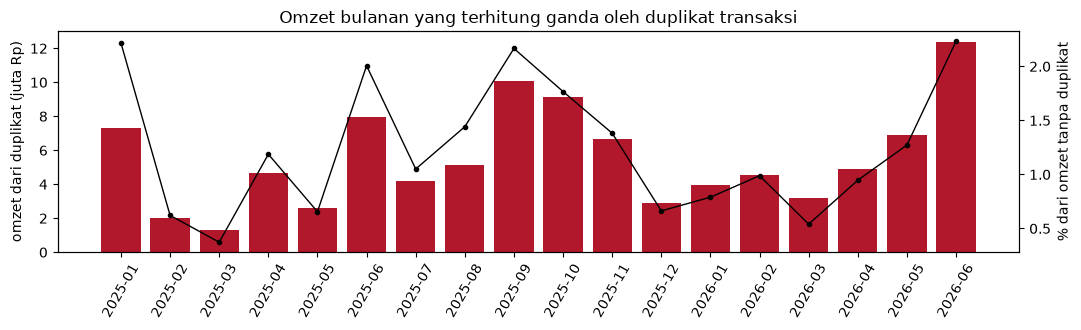

In [16]:
omzet["selisih"] = omzet.dengan_duplikat - omzet.tanpa_duplikat
omzet["selisih_persen"] = 100 * omzet.selisih / omzet.tanpa_duplikat
B["omzet_dengan"], B["omzet_tanpa"] = float(omzet.dengan_duplikat.sum()), float(omzet.tanpa_duplikat.sum())
B["omzet_lebih"] = B["omzet_dengan"] - B["omzet_tanpa"]
B["omzet_lebih_persen"] = 100 * B["omzet_lebih"] / B["omzet_tanpa"]
B["bulan_terdampak"] = str(omzet.selisih_persen.idxmax()), float(omzet.selisih_persen.max())
yatim = ~t3.kode_produk.isin(produk.kode_produk)
anomali = pd.DataFrame({
    "A-05 jumlah negatif": t3.jumlah_metode.ne("teramati"),
    "A-06 harga x100": t3.harga_satuan_metode.ne("teramati"),
    "A-07 diskon pecahan": pecahan, "A-16 kode yatim": yatim})
B["anomali_ganda"] = pd.DataFrame({"dengan_duplikat": anomali.sum(), "tanpa_duplikat": anomali[~dibuang].sum()})
print(f"omzet selesai: {angka(B['omzet_dengan'])} vs {angka(B['omzet_tanpa'])} juta Rp; duplikat menambah "
      f"{angka(B['omzet_lebih'])} juta ({angka(B['omzet_lebih_persen'], 2)}%); "
      f"bulan terdampak terbesar {B['bulan_terdampak'][0]} ({angka(B['bulan_terdampak'][1], 2)}%)")
print(B["anomali_ganda"].to_string())

fig, ax = plt.subplots(figsize=(11, 3.4))
x = omzet.index.astype(str)
ax.bar(x, omzet.selisih, color="#b2182b")
ax.set_ylabel("omzet dari duplikat (juta Rp)"); ax.tick_params(axis="x", rotation=60)
ax2 = ax.twinx(); ax2.plot(x, omzet.selisih_persen, "k.-", lw=1); ax2.set_ylabel("% dari omzet tanpa duplikat")
ax.set_title("Omzet bulanan yang terhitung ganda oleh duplikat transaksi")
fig.tight_layout(); fig.savefig(OUT / "02_duplikat_omzet.png", dpi=110, bbox_inches="tight"); plt.show()

### B.4 Total bayar dan kode produk di luar katalog

In [17]:
total_asli = pd.to_numeric(t3.total_bayar)
rumus = t3.jumlah.astype("Float64") * t3.harga_satuan * (1 - diskon_baru / 100) + t3.ongkir
selisih = (total_asli - rumus).round(2)
benar = lambda m: m.fillna(False).to_numpy(dtype=bool)  # noqa: E731
kelas = pd.Series(np.select([benar(selisih.isna()), benar(selisih.abs().le(1)), benar((selisih - 10_000).abs().le(1))],
                            ["tidak_dapat_dihitung", "cocok", "lebih_10000"], "lain"), index=t3.index)
pd.crosstab(t3.ongkir_metode, kelas, margins=True)

col_0,cocok,lain,lebih_10000,tidak_dapat_dihitung,All
ongkir_metode,,,,,
deduktif,1049,0,0,0,1049
median_provinsi,39,23,0,0,62
teramati,23061,0,115,1,23177
All,24149,23,115,1,24288


In [18]:
teramati = t3.ongkir_metode.eq("teramati")
koreksi_total = kelas.eq("lebih_10000") & teramati
total_baru = total_asli.where(~koreksi_total, total_asli - 10_000)
total_metode = pd.Series(np.where(koreksi_total, "koreksi_kurang_10000", "teramati"), index=t3.index)
total_status = pd.Series(np.select([koreksi_total, kelas.eq("cocok") & teramati],
                                   ["kesalahan_dikoreksi", "wajar"], "tidak_dapat_diperiksa"), index=t3.index)
B["total_kelas"] = pd.crosstab(t3.ongkir_metode, kelas)
B["total_10000"] = int(koreksi_total.sum())
B["total_10000_tanpa_dup"] = int((koreksi_total & ~dibuang).sum())
B["total_tak_diperiksa"] = int(total_status.eq("tidak_dapat_diperiksa").sum())
# Modul 3: ongkir isian median yang prasyarat deduktifnya gagal karena harga x100/jumlah negatif
median_isian = t3.ongkir_metode.eq("median_provinsi")
terkoreksi_m03 = t3.harga_satuan_metode.ne("teramati") | t3.jumlah_metode.ne("teramati")
ongkir_turunan = total_asli - t3.jumlah.astype("Float64") * t3.harga_satuan * (1 - diskon_baru / 100)
dapat_turun = benar(median_isian & terkoreksi_m03 & ongkir_turunan.ge(0) & (ongkir_turunan % 500).eq(0))
B["ongkir_turunan"] = int(dapat_turun.sum())
beda_turun = dapat_turun & benar(ongkir_turunan.ne(t3.ongkir))
B["ongkir_turunan_beda"] = int(beda_turun.sum())
B["ongkir_turunan_selisih"] = [rp(x) for x in (ongkir_turunan - t3.ongkir)[beda_turun]]
produk_dikenal = t3.kode_produk.isin(produk.kode_produk)
B["yatim"], B["yatim_tanpa_dup"] = int((~produk_dikenal).sum()), int((~produk_dikenal & ~dibuang).sum())
print(B["total_kelas"].to_string())
print(f"total +Rp10.000 berongkir teramati: {B['total_10000']} ({B['total_10000_tanpa_dup']} setelah duplikat dibuang);",
      f"tidak dapat diperiksa {B['total_tak_diperiksa']}")
print(f"ongkir isian median kini dapat diturunkan: {B['ongkir_turunan']}, berbeda {B['ongkir_turunan_beda']} "
      f"{B['ongkir_turunan_selisih']}")
print(f"kode produk di luar katalog: {B['yatim']} ({B['yatim_tanpa_dup']} setelah duplikat dibuang)")

col_0            cocok  lain  lebih_10000  tidak_dapat_dihitung
ongkir_metode                                                  
deduktif          1049     0            0                     0
median_provinsi     39    23            0                     0
teramati         23061     0          115                     1
total +Rp10.000 berongkir teramati: 115 (112 setelah duplikat dibuang); tidak dapat diperiksa 1112
ongkir isian median kini dapat diturunkan: 10, berbeda 2 ['Rp88.000', 'Rp20.500']
kode produk di luar katalog: 77 (76 setelah duplikat dibuang)


**Pembahasan B**

| Pemeriksaan | Hasil |
|---|---:|
| salinan eksak (18 kolom identik) | **192** |
| salinan dekat (17 kolom identik, id `LS-tttt-9xxxxx`) | **96** baris pada 96 nomor pesanan |
| kelompok kembar 2 / 3 baris | 286 / 1 (asli + salinan eksak + salinan dekat) |
| baris dibuang → baris tersisa | 288 → **24.000** |
| `drop_duplicates("id_pesanan")` | akan membuang **8.448 baris sah** (6.400 pesanan multi-baris) |
| omzet selesai terhitung ganda | Rp99,8 juta (**+1,24%**); bulan terburuk Juni 2026 +2,23% |
| total bayar tepat +Rp10.000 (ongkir teramati) | **115** dikoreksi (112 setelah duplikat dibuang) |

- **Kunci bisnis yang benar adalah `(id_pesanan, baris_ke)`**, bukan `id_pesanan`: satu pesanan
  dapat memuat sampai empat baris produk. Duplikat eksak justru tampak sebagai kunci bisnis ganda
  (192), sedangkan duplikat dekat **lolos** dari pemeriksaan kunci karena nomornya baru.
- **Bukti kirim ulang.** Salinan dekat identik sampai ke detik `waktu_pesan`, pelanggan, produk,
  dan total; nomornya berasal dari rentang 900000-an yang tidak pernah dipakai pesanan biasa; dan
  **34 dari 96** nomor 9xxxxx tidak memuat `baris_ke` 1, sesuatu yang mustahil untuk pesanan
  asli. Yang tersalin adalah *baris*, bukan pesanan. Kebetulan murni hampir mustahil: di luar
  kelompok kembar hanya 2 nilai `waktu_pesan` dipakai dua pesanan berbeda, dan keduanya berbeda
  pada kolom lain.
- **Yang dipertahankan** adalah baris ber-id biasa yang paling awal; seluruh id 9xxxxx dibuang.
  Setiap baris yang dibuang tercatat dengan id dan posisi barisnya di `duplikat_transaksi_m04.csv`,
  sehingga `baris_m03 = baris_m04 + dibuang` (24.288 = 24.000 + 288).
- **Anomali ikut tersalin.** Harga ×100 119 → 117, jumlah negatif 70 → 68, diskon pecahan 515 →
  510, kode yatim 77 → 76: angka setelah pembuangan sama dengan yang ditanam, sehingga register
  Modul 1 yang dihitung sebelum deduplikasi melebih-lebihkan setiap anomali.
- **Total bayar.** Pada 23.177 baris berongkir teramati, identitas `total_bayar` cocok pada
  23.061, lebih tepat **Rp10.000** pada 115, dan tidak pernah meleset dengan jumlah lain:
  selisih yang konstan itu adalah kesalahan sistematis (A-08) yang nilai benarnya dapat
  diturunkan, sehingga dikoreksi dengan `total_bayar_metode = koreksi_kurang_10000`. Register
  Modul 1 mencatat 751 baris tidak cocok; sebagian besar ternyata akibat diskon pecahan, harga
  ×100, dan jumlah negatif yang kini sudah dibetulkan, bukan kesalahan `total_bayar`. Pada 1.111
  baris berongkir isian Modul 2 identitas **tidak dapat menjadi saksi**: ongkir deduktif dihitung
  dari total itu sendiri (selalu cocok, melingkar), dan ongkir median adalah tebakan; statusnya
  `tidak_dapat_diperiksa`. Satu baris lagi tidak dapat dihitung karena `jumlah` dikosongkan Modul 3.
- **Ongkir isian yang kini dapat diturunkan** (temuan Modul 3): 10 baris, 2 berbeda dari isian
  median (Rp88.000 dan Rp20.500). Modul 4 tidak mengubah `ongkir` (milik Modul 2) dan mencatat
  penundaan ini pada log: urutan "koreksi kesalahan nilai sebelum imputasi" ditegakkan pada
  pipeline Modul 9.
- `produk_dikenal = False` pada 77 baris (76 setelah duplikat dibuang); kodenya dipertahankan
  karena transaksinya nyata, tetapi Modul 8 akan menolaknya pada kunci asing.

## Bagian C — Duplikat pelanggan web

### C.1 Normalisasi untuk pencocokan

In [19]:
def normal_hp(teks: pd.Series) -> pd.Series:
    """Nomor HP Indonesia -> E.164 (+628...). Berhenti bila ada nomor di luar pola, alih-alih
    mengembalikan teks asli diam-diam."""
    digit = teks.str.replace(r"\D", "", regex=True).str.replace(r"^0", "62", regex=True)
    e164 = "+" + digit
    salah = ~e164.str.fullmatch(r"\+628\d{7,11}")
    if salah.any():
        raise ValueError(f"{int(salah.sum())} nomor tidak dapat dinormalisasi: {teks[salah].unique()[:5]}")
    return e164


def kunci_nama(teks: pd.Series) -> pd.Series:
    """Nama untuk dibandingkan: huruf kecil, spasi dirapatkan."""
    return teks.str.casefold().str.strip().str.replace(r"\s+", " ", regex=True)


print("baris web:", len(web), "| salinan eksak:", int(web.duplicated().sum()),
      "| id_pelanggan ganda:", int(web.id_pelanggan.duplicated().sum()))
web.no_hp.str.replace(r"\d", "9", regex=True).value_counts().to_frame("baris")

baris web: 3260 | salinan eksak: 100 | id_pelanggan ganda: 100


,baris
no_hp,
9999-9999-9999,1168
+99 999 9999 9999,772
999999999999,682
9999999999999,638


In [20]:
id_ganda = web.id_pelanggan.duplicated(keep=False)
assert web[id_ganda].duplicated(keep=False).all(), "id_pelanggan ganda selalu salinan eksak"
B["web_eksak"] = int(web.duplicated().sum())
wu = web.drop_duplicates().reset_index(drop=True)
assert wu.id_pelanggan.is_unique
wu["hp"] = normal_hp(wu.no_hp)
wu["nama_k"] = kunci_nama(wu.nama)
wu["email_k"] = wu.email.str.strip().str.casefold()
B["web_unik"] = len(wu)
email_ganda = wu[wu.email_k.duplicated(keep=False)]
B["email_bersama_id"], B["email_bersama"] = len(email_ganda), email_ganda.email_k.nunique()
per_email = email_ganda.groupby("email_k").agg(hp=("hp", "nunique"), lahir=("tgl_lahir", "nunique"))
B["email_bersama_beda_hp"] = int(per_email.hp.gt(1).sum())
B["email_bersama_beda_lahir"] = int(per_email.lahir.gt(1).sum())
B["nama_unik"] = wu.nama_k.nunique()
B["nama_bersama_id"] = int(wu.nama_k.duplicated(keep=False).sum())
print(f"web: {len(web)} baris -> {B['web_unik']} id unik ({B['web_eksak']} salinan eksak)")
print(f"email dipakai lebih dari satu id: {B['email_bersama']} email, {B['email_bersama_id']} id; "
      f"nomor HP berbeda {B['email_bersama_beda_hp']}, tanggal lahir berbeda {B['email_bersama_beda_lahir']}")
print(f"nama: {B['nama_unik']} nama berbeda untuk {B['web_unik']} pelanggan; "
      f"{B['nama_bersama_id']} pelanggan berbagi nama dengan pelanggan lain")
email_ganda.sort_values("email_k")[["id_pelanggan", "nama", "email", "no_hp", "kota", "tgl_lahir"]].head(6)

web: 3260 baris -> 3160 id unik (100 salinan eksak)
email dipakai lebih dari satu id: 20 email, 40 id; nomor HP berbeda 20, tanggal lahir berbeda 20
nama: 704 nama berbeda untuk 3160 pelanggan; 3084 pelanggan berbagi nama dengan pelanggan lain


,id_pelanggan,nama,email,no_hp,kota,tgl_lahir
335,W-01631,Ahmad Rahmawati,ahmad.rahmawati44@mail.id,0832-7122-1457,MEDAN,1997-07-17
938,W-01908,Ahmad Rahmawati,ahmad.rahmawati44@mail.id,0863-9235-5511,Kota Banda Aceh,1970-01-23
755,W-00907,Ahmad Rahmawati,ahmad.rahmawati95@mail.id,0892-9979-9484,Pekan Baru,1972-10-01
1791,W-00624,Ahmad Rahmawati,ahmad.rahmawati95@mail.id,0805-3684-7179,Kota Padang,1992-06-21
846,W-00939,Andi Putra,andi.putra89@yahoo.co.id,087599567948,Batam,1989-05-07
2116,W-01138,Andi Putra,andi.putra89@yahoo.co.id,0800-2869-0000,Medan,1993-01-02


### C.2 Biaya perbandingan dan *blocking*

In [21]:
def pasangan_blok(df: pd.DataFrame, kunci: str) -> pd.DataFrame:
    """Seluruh pasangan (a, b), a < b, di dalam blok yang nilai `kunci`-nya sama."""
    kiri = df[["id_pelanggan", kunci]]
    p = kiri.merge(kiri, on=kunci, suffixes=("_a", "_b"))
    return p[p.id_pelanggan_a < p.id_pelanggan_b].reset_index(drop=True)


n = len(wu)
contoh = wu.nama_k.sample(400, random_state=SEED).tolist()
mulai = time.perf_counter()
process.cdist(contoh, contoh, scorer=fuzz.token_sort_ratio)
detik = time.perf_counter() - mulai
print(f"tanpa blocking: {n * (n - 1) // 2:,} pasangan web x web".replace(",", "."))
print(f"400 x 400 nama dalam {detik:.3f} detik -> perkiraan web x web {detik * (n / 400) ** 2:.1f} detik")

tanpa blocking: 4.991.220 pasangan web x web
400 x 400 nama dalam 0.039 detik -> perkiraan web x web 2.4 detik


In [22]:
semua_pasangan = n * (n - 1) // 2
wu["kota_k"] = web_kota.loc[wu.index].to_numpy() if len(web_kota) == len(wu) else wu.kota.map(peta_kota)
baris_blok = [{"strategi": "tanpa_blocking", "n_blok": 1, "pasangan_kandidat": semua_pasangan,
               "persen_dari_semua": 100.0, "blok_terbesar": n}]
for strategi, kunci_blok, d in [("no_hp", "hp", wu), ("tgl_lahir", "tgl_lahir", wu),
                                ("tgl_lahir_tanpa_penanda", "tgl_lahir", wu[wu.tgl_lahir.ne("1900-01-01")]),
                                ("kota", "kota_k", wu), ("nama_identik", "nama_k", wu)]:
    ukuran_blok = d.groupby(kunci_blok).size()
    pasangan = int((ukuran_blok * (ukuran_blok - 1) // 2).sum())
    baris_blok.append({"strategi": strategi, "n_blok": int(ukuran_blok.gt(1).sum()), "pasangan_kandidat": pasangan,
                       "persen_dari_semua": round(100 * pasangan / semua_pasangan, 4),
                       "blok_terbesar": int(ukuran_blok.max())})
blok = pd.DataFrame(baris_blok)
blok.to_csv(OUT / "blocking_m04.csv", index=False)
B["blok"] = blok.set_index("strategi")
B["penanda_1900"] = int(wu.tgl_lahir.eq("1900-01-01").sum())
B["cdist_detik"], B["cdist_perkiraan"] = detik, detik * (n / 400) ** 2
blok

,strategi,n_blok,pasangan_kandidat,persen_dari_semua,blok_terbesar
0,tanpa_blocking,1,4991220,100.0000,3160
1,no_hp,60,60,0.0012,2
2,tgl_lahir,335,3573,0.0716,80
3,tgl_lahir_tanpa_penanda,334,413,0.0083,4
4,kota,10,641352,12.8496,676
5,nama_identik,628,7340,0.1471,13


### C.3 Skor nama dan ambang

In [23]:
def skor_nama(p: pd.DataFrame, nama: pd.Series) -> pd.DataFrame:
    """Tambahkan token_sort_ratio (0-100) dan Jaro-Winkler (0-1) antara nama a dan nama b."""
    a, b = p.id_pelanggan_a.map(nama), p.id_pelanggan_b.map(nama)
    return p.assign(tsr=[fuzz.token_sort_ratio(x, y) for x, y in zip(a, b)],
                    jw=[JaroWinkler.similarity(x, y) for x, y in zip(a, b)])


nama_k = wu.set_index("id_pelanggan").nama_k
p_hp = skor_nama(pasangan_blok(wu, "hp"), nama_k)
p_lahir = skor_nama(pasangan_blok(wu, "tgl_lahir"), nama_k)
print("pasangan blok no_hp:", len(p_hp), "| pasangan blok tgl_lahir:", len(p_lahir))
p_hp.describe().loc[["min", "25%", "50%", "max"], ["tsr", "jw"]]

pasangan blok no_hp: 60 | pasangan blok tgl_lahir: 3573


,tsr,jw
min,34.782609,0.846429
25%,66.000000,0.877778
50%,84.461153,0.896250
max,100.000000,1.000000


blok no_hp: 60 pasangan; 30 berupa inisial (tsr (34.78260869565217, 73.6842105263158)); jw minimum 0.846
skor  ambang  lolos_blok_tgl_lahir  hp_sama  hp_berbeda  hp_berbeda_di_1900  blok_hp_tertangkap
 tsr   80.00                    45       30          15                  14                  30
 tsr   85.00                    38       30           8                   7                  30
 tsr   90.00                    36       30           6                   5                  30
 tsr   95.00                    36       30           6                   5                  30
  jw    0.85                   144       59          85                  79                  59
  jw    0.90                    49       30          19                  17                  30
  jw    0.93                    30       24           6                   5                  24
  jw    0.95                    28       22           6                   5                  22


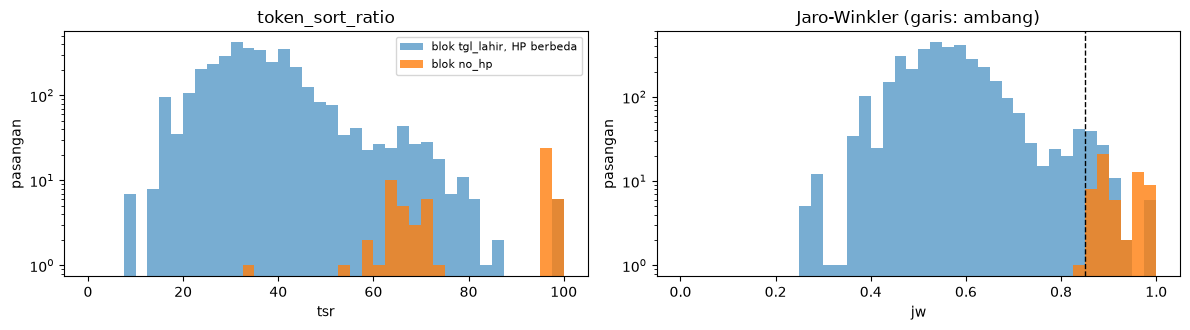

In [24]:
hp_web = wu.set_index("id_pelanggan").hp
p_lahir["hp_sama"] = p_lahir.id_pelanggan_a.map(hp_web).eq(p_lahir.id_pelanggan_b.map(hp_web))
p_lahir["penanda"] = p_lahir.tgl_lahir.eq("1900-01-01")


def inisial_cocok(a: str, b: str) -> bool:
    """'irfan w.' vs 'irfan wijaya': nama depan sama dan inisial cocok dengan nama belakang."""
    x, y = a.split(), b.split()
    if len(x) != 2 or len(y) != 2 or x[0] != y[0]:
        return False
    pendek, panjang = sorted([x[1], y[1]], key=len)
    return len(pendek) == 2 and pendek.endswith(".") and panjang.startswith(pendek[0])


for p in (p_hp, p_lahir):
    p["inisial"] = [inisial_cocok(nama_k[a], nama_k[b]) for a, b in zip(p.id_pelanggan_a, p.id_pelanggan_b)]
B["hp_inisial"] = int(p_hp.inisial.sum())
B["hp_tsr_inisial"] = (float(p_hp.tsr[p_hp.inisial].min()), float(p_hp.tsr[p_hp.inisial].max()))
B["hp_jw_min"] = float(p_hp.jw.min())
ambang = []
for skor, nilai in [("tsr", [80, 85, 90, 95]), ("jw", [.85, .90, .93, .95])]:
    for t in nilai:
        lolos = p_lahir[skor].ge(t)
        ambang.append({"skor": skor, "ambang": t, "lolos_blok_tgl_lahir": int(lolos.sum()),
                       "hp_sama": int((lolos & p_lahir.hp_sama).sum()),
                       "hp_berbeda": int((lolos & ~p_lahir.hp_sama).sum()),
                       "hp_berbeda_di_1900": int((lolos & ~p_lahir.hp_sama & p_lahir.penanda).sum()),
                       "blok_hp_tertangkap": int(p_hp[skor].ge(t).sum())})
B["ambang_web"] = pd.DataFrame(ambang)
AMBANG_JW = 0.85
print(f"blok no_hp: {len(p_hp)} pasangan; {B['hp_inisial']} berupa inisial (tsr {B['hp_tsr_inisial']}); "
      f"jw minimum {B['hp_jw_min']:.3f}")
print(B["ambang_web"].to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, skor, bins in [(axes[0], "tsr", np.linspace(0, 100, 41)), (axes[1], "jw", np.linspace(0, 1, 41))]:
    ax.hist(p_lahir[skor][~p_lahir.hp_sama], bins=bins, alpha=.6, label="blok tgl_lahir, HP berbeda")
    ax.hist(p_hp[skor], bins=bins, alpha=.8, label="blok no_hp")
    ax.set_yscale("log"); ax.set_xlabel(skor); ax.set_ylabel("pasangan")
axes[1].axvline(AMBANG_JW, color="k", ls="--", lw=1); axes[0].legend(fontsize=8)
axes[0].set_title("token_sort_ratio"); axes[1].set_title("Jaro-Winkler (garis: ambang)")
fig.tight_layout(); fig.savefig(OUT / "03_skor_nama.png", dpi=110, bbox_inches="tight"); plt.show()

### C.4 Keputusan pasangan web–web

In [25]:
# Aturan penerimaan pasangan web-web dari C.3
terima_web = p_hp[p_hp.jw.ge(AMBANG_JW) | p_hp.inisial].copy()
terima_web["aturan"] = "hp_sama_nama_cocok"
terima_web[["id_pelanggan_a", "id_pelanggan_b", "aturan", "tsr", "jw"]].to_csv(OUT / "pasangan_web_m04.csv", index=False)
print("pasangan web-web diterima:", len(terima_web), "dari", len(p_hp), "pasangan blok no_hp")

pasangan web-web diterima: 60 dari 60 pasangan blok no_hp


In [26]:
id_baru = terima_web[["id_pelanggan_a", "id_pelanggan_b"]].max(axis=1)
B["web_dekat"] = len(terima_web)
B["transaksi_id_dekat"] = int(mentah.id_pelanggan.isin(id_baru).sum())
B["transaksi_id_dekat_unik"] = int(mentah.id_pelanggan[mentah.id_pelanggan.isin(id_baru)].nunique())
print(f"{B['transaksi_id_dekat']} baris transaksi merujuk {B['transaksi_id_dekat_unik']} id pendaftaran ulang;",
      "menghapus id itu membuat transaksinya yatim")

259 baris transaksi merujuk 54 id pendaftaran ulang; menghapus id itu membuat transaksinya yatim


**Pembahasan C**

| Pemeriksaan | Hasil |
|---|---:|
| salinan eksak web (id ikut tersalin) | **100** → 3.160 id unik |
| email dipakai lebih dari satu id | **20 email**, 40 id: seluruhnya berbeda nomor HP **dan** tanggal lahir |
| nama berbeda untuk 3.160 pelanggan | **704**; 3.084 pelanggan berbagi nama dengan orang lain |
| pasangan tanpa *blocking* | 4.991.220 |
| blok `no_hp` / `tgl_lahir` / `kota` | **60** / 3.573 / 641.352 pasangan |
| blok `tgl_lahir` terbesar | **80** pelanggan bertanggal `1900-01-01` (penanda) = 3.160 dari 3.573 pasangan |
| pasangan berbagi nama identik | 7.340 |

- **Email bukan identitas.** Dua puluh email dipakai dua orang yang berbeda nomor HP dan tanggal
  lahirnya: alamat dibentuk dari nama dan angka pendek, sehingga nama pasaran bertabrakan. Nama
  lebih buruk lagi: hanya 704 nama untuk 3.160 orang. Tanpa *blocking*, pencocokan nama akan
  menerima ribuan pasangan beda orang yang skornya 100.
- ***Blocking* mengubah biaya dan mutu sekaligus.** Blok `no_hp` menyisakan 60 pasangan
  (0,0012% dari 5 juta), seluruhnya kandidat kuat. Blok `tgl_lahir` tampak murah, tetapi
  **penanda `1900-01-01` membuat satu blok raksasa** (80 orang, 88% pasangan blok itu) yang
  menyatukan orang yang sama-sama tidak mengisi tanggal lahir. Penanda harus dikeluarkan sebelum
  menjadi kunci blok, sama seperti pada Modul 2.
- **Dua puncak skor.** Di blok `no_hp`, 30 pasangan berupa inisial (`irfan wijaya` vs
  `irfan w.`) dengan `token_sort_ratio` hanya **35–74**; 30 lainnya salah ketik (`indaah`) dengan
  skor tinggi. Ambang tsr ≥ 80 pun menolak separuh duplikat yang benar. Jaro-Winkler memberi
  bobot pada awalan, sehingga seluruh 60 pasangan ≥ **0,846** (59 di antaranya ≥ 0,85); aturan
  akhir: nomor HP sama **dan** (Jaro-Winkler ≥ 0,85 **atau** inisial cocok) → **60 pasangan**
  diterima.
- Di blok `tgl_lahir`, ambang jw ≥ 0,85 meloloskan 144 pasangan; **85 di antaranya berbeda nomor
  HP**, 79 di blok penanda 1900. Skor nama tinggi + tanggal lahir sama bukan bukti bila tanggal
  itu penanda.
- **Pendaftaran ulang tidak dihapus.** 259 baris transaksi merujuk 54 id pendaftaran ulang;
  menghapus id itu membuat transaksinya yatim. Kedua id dipertahankan dan disatukan lewat
  `id_entitas` pada Bagian D.

## Bagian D — Resolusi entitas web ↔ aplikasi

### D.1 Satu skema untuk dua sumber

In [27]:
def urai_tanggal(teks: pd.Series, formats: list[str]) -> pd.Series:
    """Urai tanggal dengan daftar format eksplisit secara berurutan; berhenti bila ada sisa."""
    hasil = pd.Series(pd.NaT, index=teks.index, dtype="datetime64[us]")
    for f in formats:
        isi = hasil.isna()
        hasil[isi] = pd.to_datetime(teks[isi], format=f, errors="coerce")
    if hasil.isna().any():
        raise ValueError(f"{int(hasil.isna().sum())} tanggal tidak terurai: {teks[hasil.isna()].unique()[:5]}")
    return hasil


tgl_web = urai_tanggal(wu.tgl_daftar, ["%Y-%m-%d", "%d/%m/%Y", "%d-%b-%Y"])   # dd/mm: Latihan 4.1
pel_web = pd.DataFrame({
    "id_pelanggan": wu.id_pelanggan, "sumber": "web", "nama": wu.nama, "email": wu.email_k,
    "no_hp": wu.hp, "kota": wu.kota.map(peta_kota), "provinsi": wu.provinsi.map(peta_prov),
    "jenis_kelamin_asli": wu.jenis_kelamin, "tanggal_daftar": tgl_web, "tanggal_daftar_asli": wu.tgl_daftar,
    "lahir_asli": wu.tgl_lahir, "no_hp_asli": wu.no_hp,
    "salinan_eksak_dibuang": wu.id_pelanggan.map(web.id_pelanggan.value_counts() - 1)})
pel_app = pd.DataFrame({
    "id_pelanggan": app.customer_id, "sumber": "app", "nama": app.full_name,
    "email": app.email_address.str.strip().str.casefold(), "no_hp": normal_hp(app.phone),
    "kota": app.city.map(peta_kota), "jenis_kelamin_asli": app.gender,
    "tanggal_daftar_asli": app.registered_at, "lahir_asli": app.birth_year,
    "no_hp_asli": app.phone, "salinan_eksak_dibuang": 0})
print(app.gender.value_counts(dropna=False).to_dict(), app.birth_year.head(3).tolist())

{'M': 667, 'male': 639, 'F': 598, 'female': 584, '': 112} ['1996.0', '1982.0', '1981.0']


In [28]:
peta_jk = {"L": "L", "l": "L", "Laki-laki": "L", "M": "L", "male": "L",
           "P": "P", "p": "P", "Perempuan": "P", "F": "P", "female": "P", "": pd.NA}
pel_web["jenis_kelamin"] = petakan(wu.jenis_kelamin, peta_jk, "pelanggan_web.jenis_kelamin")
pel_app["jenis_kelamin"] = petakan(app.gender, peta_jk, "pelanggan_app.gender")
pel_app["tanggal_daftar"] = (pd.to_datetime(app.registered_at, format="%Y-%m-%dT%H:%M:%SZ")
                             .dt.tz_localize("UTC").dt.tz_convert("Asia/Jakarta").dt.tz_localize(None))
pel_app["provinsi"] = pel_app.kota.map(KOTA_LAYANAN)
pel_web["tahun_lahir"] = pd.to_datetime(wu.tgl_lahir, format="%Y-%m-%d").dt.year.astype("Int64").mask(
    wu.tgl_lahir.eq("1900-01-01"))
pel_app["tahun_lahir"] = pd.to_numeric(app.birth_year.replace("", np.nan)).round().astype("Int64")
pel = pd.concat([pel_web, pel_app], ignore_index=True)
pel["nama_asli"] = pel.nama
pel["nama"] = pel.nama.str.strip().str.replace(r"\s+", " ", regex=True).str.title()
pel["nama_k"] = kunci_nama(pel.nama)
assert pel.id_pelanggan.is_unique and pel.kota.notna().all() and pel.provinsi.notna().all()
B["pel_web"], B["pel_app"], B["pel_total"] = len(pel_web), len(pel_app), len(pel)
B["jk_kosong"] = int(pel.jenis_kelamin.isna().sum())
B["lahir_penanda"] = int(wu.tgl_lahir.eq("1900-01-01").sum())
B["lahir_app_kosong"] = int(app.birth_year.eq("").sum())
print(f"pelanggan: web {B['pel_web']} + app {B['pel_app']} = {B['pel_total']} id;",
      f"jenis kelamin kosong {B['jk_kosong']}; tahun lahir penanda web {B['lahir_penanda']}, kosong app {B['lahir_app_kosong']}")
pel.groupby("sumber")[["jenis_kelamin", "tahun_lahir"]].agg(lambda s: s.isna().mean().round(3))

pelanggan: web 3160 + app 2600 = 5760 id; jenis kelamin kosong 218; tahun lahir penanda web 80, kosong app 252


,jenis_kelamin,tahun_lahir
sumber,,
app,0.043,0.097
web,0.034,0.025


### D.2 Aturan pencocokan bertingkat

In [29]:
KOLOM_P = ["id_pelanggan", "nama_k", "email", "no_hp", "kota", "tanggal_daftar", "tahun_lahir"]
w_, a_ = pel.loc[pel.sumber.eq("web"), KOLOM_P], pel.loc[pel.sumber.eq("app"), KOLOM_P]
lokal = lambda d: d.assign(lokal=d.email.str.split("@").str[0])  # noqa: E731

# tingkat 1: nomor HP E.164 sama
tk1 = a_.merge(w_, on="no_hp", suffixes=("_app", "_web"))
sisa_a = a_[~a_.id_pelanggan.isin(tk1.id_pelanggan_app)]
sisa_w = w_[~w_.id_pelanggan.isin(tk1.id_pelanggan_web)]
# tingkat 2: bagian lokal email sama (domain boleh berbeda, misalnya icloud.com)
tk2 = lokal(sisa_a).merge(lokal(sisa_w), on="lokal", suffixes=("_app", "_web"))


def kandidat_nama(a: pd.DataFrame, w: pd.DataFrame, ambang: float = 0.9) -> pd.DataFrame:
    """Tingkat 3: pasangan app-web SEKOTA yang Jaro-Winkler namanya >= ambang (blocking: kota)."""
    hasil = []
    for kota, ga in a.groupby("kota"):
        gw = w[w.kota.eq(kota)]
        m = process.cdist(ga.nama_k.tolist(), gw.nama_k.tolist(),
                          scorer=JaroWinkler.normalized_similarity, score_cutoff=ambang)
        i, j = np.nonzero(m)
        hasil.append(pd.DataFrame({"id_pelanggan_app": ga.id_pelanggan.to_numpy()[i],
                                   "id_pelanggan_web": gw.id_pelanggan.to_numpy()[j], "jw": m[i, j]}))
    return pd.concat(hasil, ignore_index=True)


tk3 = kandidat_nama(sisa_a[~sisa_a.id_pelanggan.isin(tk2.id_pelanggan_app)], sisa_w, 0.9)
print(f"tingkat 1 (no_hp): {len(tk1)} pasangan, {tk1.id_pelanggan_app.nunique()} id app | "
      f"tingkat 2 (email lokal): {len(tk2)} | tingkat 3 (nama >= 0,9 sekota): {len(tk3)}")

tingkat 1 (no_hp): 716 pasangan, 700 id app | tingkat 2 (email lokal): 69 | tingkat 3 (nama >= 0,9 sekota): 2534


In [30]:
info = pel.set_index("id_pelanggan")


def bukti(p: pd.DataFrame) -> pd.DataFrame:
    """Bukti penguat untuk pasangan app-web: tanggal daftar, tahun lahir, dan skor nama."""
    ambil = lambda kolom, sisi: p[f"id_pelanggan_{sisi}"].map(info[kolom])  # noqa: E731
    ya, yw = ambil("tahun_lahir", "app"), ambil("tahun_lahir", "web")
    return p.assign(
        tgl_sama=ambil("tanggal_daftar", "app").dt.normalize().eq(ambil("tanggal_daftar", "web").dt.normalize()),
        thn_bertentangan=(ya.notna() & yw.notna() & ya.ne(yw)).astype(bool),
        jw_nama=[JaroWinkler.similarity(x, y) for x, y in zip(ambil("nama_k", "app"), ambil("nama_k", "web"))])


ringkas = []
for tingkat, p in [("1 no_hp", tk1), ("2 email lokal", tk2), ("3 nama sekota", tk3)]:
    p = bukti(p)
    ringkas.append({"tingkat": tingkat, "kandidat": len(p), "tanggal_daftar_sama": int(p.tgl_sama.sum()),
                    "tahun_lahir_bertentangan": int(p.thn_bertentangan.sum()),
                    "didukung": int((p.tgl_sama & ~p.thn_bertentangan).sum()),
                    "jw_median": round(float(p.jw_nama.median()), 3)})
B["tingkat"] = pd.DataFrame(ringkas).set_index("tingkat")
# tanggal daftar dibandingkan dalam UTC (tanpa konversi) pada tingkat 1
utc_app = pd.to_datetime(app.registered_at, format="%Y-%m-%dT%H:%M:%SZ").set_axis(app.customer_id)
B["tk1_tgl_utc_sama"] = float(utc_app[tk1.id_pelanggan_app].dt.normalize().to_numpy()
                              .__eq__(tk1.id_pelanggan_web.map(info.tanggal_daftar).dt.normalize().to_numpy()).mean())
print(B["tingkat"].to_string())
print(f"tingkat 1: tanggal daftar sama {100 * B['tingkat'].loc['1 no_hp', 'tanggal_daftar_sama'] / len(tk1):.1f}% "
      f"dalam WIB, {100 * B['tk1_tgl_utc_sama']:.1f}% bila aplikasi dibiarkan UTC")

# keputusan: tingkat diterima hanya bila didukung bukti penguat dan tidak bertentangan
syarat = lambda p: p[p.tgl_sama & ~p.thn_bertentangan]  # noqa: E731
terima = pd.concat([syarat(bukti(tk1)).assign(aturan="hp_sama"),
                    syarat(bukti(tk2)).assign(aturan="email_lokal_dan_bukti"),
                    syarat(bukti(tk3)).assign(aturan="nama_kota_dan_bukti")], ignore_index=True)
terima["skor"] = terima.jw_nama.round(4)
B["terima_per_aturan"] = terima.aturan.value_counts().to_dict()
print("tautan web-app diterima:", B["terima_per_aturan"])

               kandidat  tanggal_daftar_sama  tahun_lahir_bertentangan  didukung  jw_median
tingkat                                                                                    
1 no_hp             716                  716                         0       716      1.000
2 email lokal        69                    0                        62         0      1.000
3 nama sekota      2534                    1                      2167         0      0.916
tingkat 1: tanggal daftar sama 100.0% dalam WIB, 69.7% bila aplikasi dibiarkan UTC
tautan web-app diterima: {'hp_sama': 716}


### D.3 *Transitive closure* dan `id_entitas`

In [31]:
def komponen(simpul: list[str], tepi: list[tuple[str, str]]) -> dict[str, str]:
    """Union-find: setiap simpul -> akar komponennya (id terkecil). Tautan a-b dan b-c
    menyatukan a, b, dan c walaupun a-c tidak pernah dibandingkan (transitive closure)."""
    induk = {s: s for s in simpul}

    def akar(x: str) -> str:
        while induk[x] != x:
            induk[x] = induk[induk[x]]
            x = induk[x]
        return x

    for a, b in tepi:
        ra, rb = akar(a), akar(b)
        if ra != rb:
            induk[max(ra, rb)] = min(ra, rb)
    return {s: akar(s) for s in simpul}


tepi = (list(zip(terima_web.id_pelanggan_a, terima_web.id_pelanggan_b))
        + list(zip(terima.id_pelanggan_app, terima.id_pelanggan_web)))
akar = pd.Series(komponen(pel.id_pelanggan.tolist(), tepi))
nomor = {a: f"E-{i + 1:05d}" for i, a in enumerate(sorted(akar.unique()))}
pel["id_entitas"] = pel.id_pelanggan.map(akar).map(nomor)
print("id sumber:", len(pel), "| entitas:", pel.id_entitas.nunique())
pel.groupby("id_entitas").size().value_counts().sort_index().to_frame("entitas")

id sumber: 5760 | entitas: 5000


,entitas
1,4256
2,728
3,16


In [32]:
ukuran_e = pel.groupby("id_entitas").size()
komposisi = pel.groupby("id_entitas").sumber.agg(lambda s: "+".join(sorted(s)))
B["entitas"] = pel.id_entitas.nunique()
B["entitas_komposisi"] = komposisi[ukuran_e.gt(1)].value_counts().to_dict()
B["entitas_tunggal"] = int(ukuran_e.eq(1).sum())
konflik = pel.dropna(subset=["tahun_lahir"]).groupby("id_entitas").tahun_lahir.nunique().gt(1)
B["entitas_konflik"] = int(konflik.sum())
assert B["entitas_konflik"] == 0
# aturan dan skor per id: tautan yang menyatukan id itu dengan id acuan entitasnya
acuan = pel.groupby("id_entitas").id_pelanggan.min()
aturan_id = {b: "hp_sama_nama_cocok" for b in terima_web.id_pelanggan_b} | {b: "hp_sama_nama_cocok" for b in terima_web.id_pelanggan_a}
aturan_id |= dict(zip(terima.id_pelanggan_web, terima.aturan)) | dict(zip(terima.id_pelanggan_app, terima.aturan))
pel["aturan"] = np.where(ukuran_e.reindex(pel.id_entitas).to_numpy() == 1, "tunggal",
                         np.where(pel.id_pelanggan.isin(acuan), "acuan", pel.id_pelanggan.map(aturan_id)))
ref_nama = pel.id_entitas.map(pel.set_index("id_pelanggan").nama_k.reindex(acuan.to_numpy()).set_axis(acuan.index))
pel["skor"] = [round(JaroWinkler.similarity(a, b), 4) for a, b in zip(pel.nama_k, ref_nama)]
pel["duplikat"] = pel.id_pelanggan.isin(terima_web[["id_pelanggan_a", "id_pelanggan_b"]].max(axis=1))
peta_entitas = pel[["id_pelanggan", "sumber", "id_entitas", "aturan", "skor"]]
peta_entitas.to_csv(OUT / "peta_entitas_m04.csv", index=False)
KOLOM_PEL = ["id_pelanggan", "sumber", "nama", "email", "no_hp", "kota", "provinsi", "jenis_kelamin",
             "tanggal_daftar", "tahun_lahir", "id_entitas", "duplikat", "nama_asli", "no_hp_asli",
             "jenis_kelamin_asli", "tanggal_daftar_asli", "lahir_asli", "salinan_eksak_dibuang"]
pelanggan_m04 = pel[KOLOM_PEL].copy()
pelanggan_m04["salinan_eksak_dibuang"] = pelanggan_m04.salinan_eksak_dibuang.astype("int64")
pelanggan_m04.to_parquet(OUT / "pelanggan_m04.parquet", index=False)
print(f"entitas {B['entitas']}: tunggal {B['entitas_tunggal']}, gabungan {B['entitas_komposisi']}; "
      f"tahun lahir bertentangan {B['entitas_konflik']}")
print("pelanggan_m04:", pelanggan_m04.shape, "| aturan:", pel.aturan.value_counts().to_dict())

entitas 5000: tunggal 4256, gabungan {'app+web': 684, 'web+web': 44, 'app+web+web': 16}; tahun lahir bertentangan 0
pelanggan_m04: (5760, 18) | aturan: {'tunggal': 4256, 'acuan': 744, 'hp_sama': 716, 'hp_sama_nama_cocok': 44}


### D.4 Memperkirakan presisi dengan sampel

In [33]:
def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    """Selang kepercayaan 95% Wilson untuk proporsi k/n."""
    p, d = k / n, 1 + z * z / n
    tengah, lebar = (p + z * z / (2 * n)) / d, z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return round(float(tengah - lebar), 3), round(float(tengah + lebar), 3)


tautan = pd.concat([
    terima_web.rename(columns={"id_pelanggan_a": "id_1", "id_pelanggan_b": "id_2"}).assign(jenis="web-web"),
    terima.rename(columns={"id_pelanggan_web": "id_1", "id_pelanggan_app": "id_2"}).assign(jenis="web-app")])
sampel = (tautan.groupby("jenis", group_keys=False).sample(15, random_state=SEED)[["jenis", "id_1", "id_2", "aturan"]]
          .reset_index(drop=True))
for i in (1, 2):
    for kolom in ["nama", "email", "kota", "tanggal_daftar", "tahun_lahir"]:
        sampel[f"{kolom}_{i}"] = sampel[f"id_{i}"].map(info[kolom] if kolom != "nama" else pel.set_index("id_pelanggan").nama)
sampel["label"] = ""          # diisi manual: sama / beda / ragu
sampel.head(4).T

,0,1,2,3
jenis,web-app,web-app,web-app,web-app
id_1,W-02770,W-02562,W-03079,W-02876
id_2,A-02270,A-02062,A-02579,A-02376
aturan,hp_sama,hp_sama,hp_sama,hp_sama
nama_1,Wulan Hasibuan,Eko Hidayat,Nurul Pratama,Hendra Sembiring
email_1,wulan.hasibuan37@mail.id,eko.hidayat87@gmail.com,nurul.pratama53@yahoo.co.id,hendra.sembiring93@mail.id
kota_1,Bengkulu,Pekanbaru,Bandar Lampung,Medan
tanggal_daftar_1,2025-05-21 00:00:00,2025-06-25 00:00:00,2025-01-01 00:00:00,2025-07-10 00:00:00
tahun_lahir_1,1997,2000,1970,1985
nama_2,Wulan Hasibuan,Eko Hidayat,Nurul Pratama,Hendra Sembiring


In [34]:
# Label diisi dengan aturan pemeriksaan tertulis agar dapat diulang: "sama" bila tidak ada bukti
# yang bertentangan dan sekurangnya dua bukti cocok (tanggal daftar, tahun lahir, nama);
# "beda" bila tahun lahir bertentangan; selain itu "ragu".
cocok_tgl = sampel.tanggal_daftar_1.dt.normalize().eq(sampel.tanggal_daftar_2.dt.normalize())
ada_thn = sampel.tahun_lahir_1.notna() & sampel.tahun_lahir_2.notna()
cocok_thn = (ada_thn & sampel.tahun_lahir_1.eq(sampel.tahun_lahir_2)).astype(bool)
cocok_nama = pd.Series([JaroWinkler.similarity(kunci_teks(a), kunci_teks(b)) >= AMBANG_JW
                        for a, b in zip(sampel.nama_1, sampel.nama_2)])
n_cocok = cocok_tgl.astype(int) + cocok_thn.astype(int) + cocok_nama.astype(int)
sampel["label"] = np.select([(ada_thn & ~cocok_thn).to_numpy(), (n_cocok >= 2).to_numpy()], ["beda", "sama"], "ragu")
sampel["alasan"] = ("tanggal daftar " + np.where(cocok_tgl, "sama", "beda") + "; tahun lahir "
                    + np.where(ada_thn, np.where(cocok_thn, "sama", "beda"), "tidak lengkap")
                    + "; nama " + np.where(cocok_nama, "cocok", "berbeda"))
sampel.to_csv(OUT / "sampel_label_m04.csv", index=False)
k_sama = int(sampel.label.eq("sama").sum())
B["sampel_sama"], B["sampel_n"], B["sampel_wilson"] = k_sama, len(sampel), wilson(k_sama, len(sampel))
print(f"label sama {k_sama}/{len(sampel)}; presisi diperkirakan {k_sama / len(sampel):.2f}, "
      f"selang 95% Wilson {B['sampel_wilson']}")
sampel.label.value_counts()

label sama 30/30; presisi diperkirakan 1.00, selang 95% Wilson (0.886, 1.0)


label
sama    30
Name: count, dtype: int64

### D.5 Menyimpan `transaksi_m04.parquet` dan log keputusan

In [35]:
hasil = t3.copy()
for kolom, baru in [("status", status_baru), ("metode_bayar", bayar_baru),
                    ("kota_tujuan", kota_baru), ("provinsi_tujuan", prov_baru)]:
    hasil[f"{kolom}_asli"] = hasil[kolom]
    hasil[kolom] = baru
hasil["diskon_persen_asli"] = hasil.diskon_persen
hasil["diskon_persen"] = diskon_baru.astype("float64")
hasil["diskon_persen_metode"] = diskon_metode
hasil["total_bayar_asli"] = hasil.total_bayar
hasil["total_bayar"] = total_baru.astype("float64")
hasil["total_bayar_metode"] = total_metode
hasil["total_bayar_status_m04"] = total_status
hasil["waktu_wib"] = waktu_bersih
hasil["waktu_format_asli"] = format_waktu
hasil["waktu_status_m04"] = waktu_status
hasil["produk_dikenal"] = produk_dikenal
hasil["duplikat_dibuang"] = pd.Series(posisi_tetap[dibuang.to_numpy()]).value_counts().reindex(
    np.arange(len(hasil)), fill_value=0).to_numpy()
hasil["id_entitas"] = hasil.id_pelanggan.map(pel.set_index("id_pelanggan").id_entitas)
transaksi_m04 = hasil[~dibuang.to_numpy()].reset_index(drop=True)

In [36]:
STATUS_M04 = {"wajar", "kesalahan_dikoreksi", "tidak_dapat_diperiksa"}
assert len(transaksi_m04) + len(duplikat) == len(t3), "rekonsiliasi: baris_m03 = baris_m04 + dibuang"
assert not transaksi_m04.duplicated(KUNCI).any(), "kunci bisnis (id_pesanan, baris_ke) harus unik"
assert set(transaksi_m04.status) <= {"selesai", "dibatalkan", "dikembalikan", "diproses"}
assert set(transaksi_m04.metode_bayar) <= set(KATEGORI_BAYAR)
assert set(transaksi_m04.kota_tujuan) <= set(KOTA_LAYANAN) and set(transaksi_m04.provinsi_tujuan) <= set(PROVINSI)
assert set(transaksi_m04.total_bayar_status_m04) <= STATUS_M04
assert transaksi_m04.waktu_wib.isna().eq(transaksi_m04.waktu_status_m04.ne("valid")).all()
tetap = transaksi_m04.total_bayar_metode.eq("teramati")
assert np.allclose(transaksi_m04.total_bayar[tetap], pd.to_numeric(transaksi_m04.total_bayar_asli[tetap]))
transaksi_m04.to_parquet(OUT / "transaksi_m04.parquet", index=False)
pd.DataFrame(PETA).to_csv(OUT / "peta_format_m04.csv", index=False)
print(transaksi_m04.shape, "->", (OUT / "transaksi_m04.parquet").name,
      f"| {len(t3)} = {len(transaksi_m04)} + {len(duplikat)} dibuang")

(24000, 46) -> transaksi_m04.parquet | 24288 = 24000 + 288 dibuang


In [37]:
KOLOM_LOG = ["id", "modul", "sumber_kolom", "temuan", "bukti", "tindakan", "alasan",
             "baris_terdampak", "id_anomali"]


def catat_keputusan(baris: list[dict], path: Path = LOG) -> pd.DataFrame:
    """Tulis ulang baris log dengan id yang sama agar notebook aman dijalankan berulang."""
    lama_log = (pd.read_csv(path, dtype=str, keep_default_na=False) if path.exists()
                else pd.DataFrame(columns=KOLOM_LOG))
    baru = pd.DataFrame(baris, columns=KOLOM_LOG).astype(str)
    log = pd.concat([lama_log[~lama_log.id.isin(baru.id)], baru]).sort_values("id")
    log.to_csv(path, index=False)
    if path.parent != MODUL:
        shutil.copyfile(path, MODUL / path.name)   # salinan untuk ZIP tugas
    return log

In [38]:
tk = B["tingkat"]
log = catat_keputusan([
    {"id": "K-04-001", "modul": 4, "sumber_kolom": "transaksi.status;transaksi.metode_bayar",
     "temuan": "status berhuruf kapital dan 16 penulisan metode bayar termasuk merek",
     "bukti": (f"status {B['status_varian']} penulisan, {B['status_kapital']} baris kapital; metode bayar "
               f"{B['bayar_varian']} penulisan -> 5 kategori, {B['bayar_berubah']} baris berubah, "
               f"merek OVO/GoPay {B['bayar_merek']} baris"),
     "tindakan": "status huruf kecil; metode_bayar dipetakan ke 5 kategori lewat peta tercatat; nilai asli di status_asli dan metode_bayar_asli",
     "alasan": "replace ad hoc tidak dapat diaudit; merek dompet digital adalah kategori E-Wallet, bukan metode baru",
     "baris_terdampak": B["status_kapital"] + B["bayar_berubah"], "id_anomali": "A-13;A-15"},
    {"id": "K-04-002", "modul": 4, "sumber_kolom": "transaksi.kota_tujuan;transaksi.provinsi_tujuan;pelanggan_web.kota;pelanggan_web.provinsi;pelanggan_app.city",
     "temuan": "penulisan kota dan provinsi beragam, termasuk singkatan",
     "bukti": (f"kota {B['kota_varian']} -> 10, provinsi {B['prov_varian']} -> 10; usulan RapidFuzz salah pada "
               f"{B['fuzzy_salah']} dari {B['fuzzy_sisa']} penulisan yang tidak terpetakan otomatis; "
               f"kota-provinsi tidak konsisten {B['transaksi_tak_konsisten']} baris"),
     "tindakan": "dipetakan lewat peta_wilayah_m04.csv; provinsi pelanggan aplikasi diturunkan dari kota",
     "alasan": "kemiripan string tidak mengenal singkatan (Sumbar, Babel, Kepri); pemetaan diputuskan dengan pengetahuan domain",
     "baris_terdampak": B["kota_berubah"], "id_anomali": "A-14"},
    {"id": "K-04-003", "modul": 4, "sumber_kolom": "transaksi.waktu_pesan",
     "temuan": "tiga format waktu, aplikasi dalam UTC, tahun 1970 dan 2062",
     "bukti": (f"{B['waktu_luar']} di luar masa operasi {B['waktu_luar_tahun']}; konversi UTC->WIB memindahkan "
               f"{B['app_ganti_tanggal']} pesanan aplikasi ke tanggal lain dan {B['app_ganti_bulan']} ke bulan lain"),
     "tindakan": "waktu_wib = urai format eksplisit, UTC -> Asia/Jakarta naif; di luar masa operasi -> NaT dengan waktu_status_m04=di_luar_rentang; waktu_pesan tetap",
     "alasan": "format='mixed' gagal atau diam-diam menukar hari dan bulan; 2062 tidak dikoreksi menjadi 2026 karena bulan dan harinya tidak terverifikasi",
     "baris_terdampak": B["app_sah"] + B["waktu_luar"], "id_anomali": "A-11;A-12"},
    {"id": "K-04-004", "modul": 4, "sumber_kolom": "transaksi.diskon_persen",
     "temuan": "diskon pecahan 0,05-0,25 pada kanal aplikasi",
     "bukti": f"{B['diskon_pecahan']} baris {B['diskon_pecahan_kanal']}; setelah dikali 100 seluruh diskon dalam {{0, 5, 10, 15, 20, 25}}",
     "tindakan": "diskon_persen dikali 100 bila 0 < d < 1; diskon_persen_metode=pecahan_dikali_100; nilai asli di diskon_persen_asli",
     "alasan": "nilai benar dapat diturunkan; menghapus atau mengosongkan membuang informasi yang ada",
     "baris_terdampak": B["diskon_pecahan"], "id_anomali": "A-07"},
    {"id": "K-04-005", "modul": 4, "sumber_kolom": "produk.harga_katalog;produk.berat;produk.kategori;produk.perlu_pendingin;produk.rating_toko",
     "temuan": "katalog produk dalam beragam format",
     "bukti": (f"kategori {B['kategori_varian']} penulisan -> {B['kategori_kanonik']} (cocok dengan kode produk: {B['kategori_prefix_cocok']}); "
               f"berat bertitik desimal {B['berat_titik']} (cara naif salah pada {B['berat_naif_salah']}); "
               f"str.title() salah pada {B['title_salah']}; rating 0,0 penanda {B['rating_penanda']}"),
     "tindakan": "produk_m04: harga_katalog_rp int, berat_gram int, kategori kanonik, perlu_pendingin bool, rating_toko NaN untuk penanda; kolom asli disimpan",
     "alasan": "kategori kanonik = ejaan terbanyak, bukan str.title(); koma dan titik keduanya pemisah desimal pada berat",
     "baris_terdampak": B["kategori_berubah"], "id_anomali": "A-18;A-19"},
    {"id": "K-04-006", "modul": 4, "sumber_kolom": "transaksi.*;transaksi.id_pesanan",
     "temuan": "duplikat transaksi eksak dan dekat (nomor pesanan 9xxxxx)",
     "bukti": (f"eksak {B['dup_eksak']}, dekat {B['dup_dekat']} identik pada 17 kolom termasuk waktu; "
               f"{B['dekat_tanpa_baris1']} dari {B['dekat_pesanan']} pesanan 9xxxxx tanpa baris_ke 1; "
               f"omzet terhitung ganda {angka(B['omzet_lebih_persen'], 2)}%"),
     "tindakan": f"{B['dup_total']} baris dibuang dari transaksi_m04 dan dicatat di duplikat_transaksi_m04.csv; dipertahankan baris ber-id biasa paling awal",
     "alasan": f"kunci bisnis (id_pesanan, baris_ke); drop_duplicates('id_pesanan') akan membuang {B['drop_id_saja']} baris sah, drop_duplicates() saja meloloskan salinan dekat",
     "baris_terdampak": B["dup_total"], "id_anomali": "A-09;A-10"},
    {"id": "K-04-007", "modul": 4, "sumber_kolom": "transaksi.total_bayar",
     "temuan": "total_bayar lebih tepat Rp10.000 dari rumus kamus data",
     "bukti": (f"ongkir teramati: cocok {int(B['total_kelas'].loc['teramati', 'cocok'])}, +10.000 {B['total_10000']}, "
               f"selisih lain 0; {B['total_tak_diperiksa']} baris tidak dapat diperiksa (ongkir isian Modul 2 atau jumlah kosong)"),
     "tindakan": "total_bayar dikurangi 10.000; total_bayar_metode=koreksi_kurang_10000; total_bayar_status_m04; nilai asli di total_bayar_asli",
     "alasan": "selisih konstan dengan saksi teramati menurunkan nilai benar; pada ongkir isian identitas melingkar sehingga tidak dikoreksi",
     "baris_terdampak": B["total_10000"], "id_anomali": "A-08"},
    {"id": "K-04-008", "modul": 4, "sumber_kolom": "transaksi.ongkir",
     "temuan": "ongkir isian median Modul 2 kini dapat diturunkan setelah koreksi Modul 3",
     "bukti": f"{B['ongkir_turunan']} baris; {B['ongkir_turunan_beda']} berbeda dari isian ({', '.join(B['ongkir_turunan_selisih'])})",
     "tindakan": "tidak diubah di Modul 4; ditunda ke pipeline Modul 9 (urutan koreksi nilai sebelum imputasi)",
     "alasan": "ongkir milik keputusan Modul 2; mengubahnya di sini memutus jejak; total_bayar baris itu berstatus tidak_dapat_diperiksa",
     "baris_terdampak": 0, "id_anomali": "A-01"},
    {"id": "K-04-009", "modul": 4, "sumber_kolom": "transaksi.kode_produk",
     "temuan": "kode produk di luar katalog (LS-UNK)",
     "bukti": f"{B['yatim']} baris ({B['yatim_tanpa_dup']} setelah duplikat dibuang)",
     "tindakan": "kode dipertahankan; bendera produk_dikenal=False",
     "alasan": "transaksinya nyata; menghapus baris menghilangkan omzet, mengganti kode berarti menebak",
     "baris_terdampak": 0, "id_anomali": "A-16"},
    {"id": "K-04-010", "modul": 4, "sumber_kolom": "pelanggan_web.*",
     "temuan": "duplikat pelanggan web eksak dan pendaftaran ulang",
     "bukti": (f"{B['web_eksak']} salinan eksak; {B['web_dekat']} pasangan no_hp sama dan nama cocok "
               f"(jw >= {AMBANG_JW} atau inisial); email dipakai bersama {B['email_bersama']} email berbeda orang"),
     "tindakan": "salinan eksak dibuang (satu baris per id); pendaftaran ulang dipertahankan dan disatukan lewat id_entitas, kolom duplikat=True",
     "alasan": f"menghapus id pendaftaran ulang membuat {B['transaksi_id_dekat']} transaksi yatim; email dan nama bukan identitas",
     "baris_terdampak": B["web_eksak"], "id_anomali": "-"},
    {"id": "K-04-011", "modul": 4, "sumber_kolom": "pelanggan_web.no_hp;pelanggan_app.phone;pelanggan_web.tgl_lahir",
     "temuan": "blocking dan ambang nama untuk pencocokan pelanggan",
     "bukti": (f"tanpa blocking {B['blok'].loc['tanpa_blocking', 'pasangan_kandidat']} pasangan; blok no_hp "
               f"{B['blok'].loc['no_hp', 'pasangan_kandidat']}; blok tgl_lahir {B['blok'].loc['tgl_lahir', 'pasangan_kandidat']} "
               f"dengan penanda 1900-01-01 {B['penanda_1900']} orang"),
     "tindakan": f"blocking pada no_hp E.164; konfirmasi nama Jaro-Winkler >= {AMBANG_JW} atau inisial cocok",
     "alasan": "token_sort_ratio menolak nama berinisial; penanda tanggal lahir tidak boleh menjadi kunci blok",
     "baris_terdampak": B["web_dekat"], "id_anomali": "-"},
    {"id": "K-04-012", "modul": 4, "sumber_kolom": "pelanggan_web.*;pelanggan_app.*",
     "temuan": "resolusi entitas web-aplikasi bertingkat",
     "bukti": (f"tingkat 1 no_hp {tk.loc['1 no_hp', 'kandidat']} kandidat, didukung {tk.loc['1 no_hp', 'didukung']}; "
               f"tingkat 2 email lokal {tk.loc['2 email lokal', 'kandidat']}, didukung {tk.loc['2 email lokal', 'didukung']}; "
               f"tingkat 3 nama sekota {tk.loc['3 nama sekota', 'kandidat']}, didukung {tk.loc['3 nama sekota', 'didukung']}; "
               f"entitas {B['entitas']} dari {B['pel_total']} id"),
     "tindakan": "tautan diterima hanya bila tanggal daftar WIB sama dan tahun lahir tidak bertentangan; transitive closure dengan union-find; peta_entitas_m04.csv",
     "alasan": "tingkat email dan nama tanpa bukti penguat hanya menambah penggabungan keliru; tanggal daftar dibandingkan dalam WIB",
     "baris_terdampak": int(pel.aturan.isin(["hp_sama", "email_lokal_dan_bukti", "nama_kota_dan_bukti"]).sum()), "id_anomali": "-"},
])
log[log.id.str.startswith("K-04-")][["id", "sumber_kolom", "baris_terdampak", "id_anomali"]]

,id,sumber_kolom,baris_terdampak,id_anomali
0,K-04-001,transaksi.status;transaksi.metode_bayar,17731,A-13;A-15
1,K-04-002,transaksi.kota_tujuan;transaksi.provinsi_tujua...,15941,A-14
2,K-04-003,transaksi.waktu_pesan,11129,A-11;A-12
3,K-04-004,transaksi.diskon_persen,515,A-07
4,K-04-005,produk.harga_katalog;produk.berat;produk.kateg...,27,A-18;A-19
5,K-04-006,transaksi.*;transaksi.id_pesanan,288,A-09;A-10
6,K-04-007,transaksi.total_bayar,115,A-08
7,K-04-008,transaksi.ongkir,0,A-01
8,K-04-009,transaksi.kode_produk,0,A-16
9,K-04-010,pelanggan_web.*,100,-


**Pembahasan D**

| Tingkat | Kandidat | Tanggal daftar WIB sama | Tahun lahir bertentangan | Diterima |
|---|---:|---:|---:|---:|
| 1 — nomor HP E.164 sama | **716** (700 id app) | 716 | 0 | **716** |
| 2 — bagian lokal email sama (sisa) | 69 | **0** | 62 | 0 |
| 3 — nama Jaro-Winkler ≥ 0,9 sekota (sisa) | 2.534 | 1 | 2.167 | 0 |

- **Tingkat pertama sudah menemukan semuanya; tingkat berikutnya hanya menemukan orang lain.**
  Pada sisa yang tidak bertaut lewat HP, hanya satu kandidat nama yang tanggal daftarnya sama,
  dan tahun lahirnya bertentangan; sebagian besar kandidat lain juga bertentangan tahun lahirnya.
  Menerima tingkat 2–3 tanpa bukti penguat akan menggabungkan seluruh kandidat itu, yang semuanya
  orang berbeda, dan lewat *transitive closure* membentuk entitas raksasa (ukur besarnya pada
  Tugas). Kaskade aturan hanya sebaik bukti penguat di setiap
  tingkatnya.
- **Tanggal daftar harus dibandingkan dalam WIB.** Pada tautan HP, tanggal daftar sama 100%
  setelah `registered_at` dikonversi ke WIB, tetapi hanya **69,7%** bila aplikasi dibiarkan UTC:
  pendaftaran pukul 00.00–07.00 WIB jatuh pada tanggal UTC sebelumnya. Bukti penguat yang salah
  zona waktu akan menolak sepertiga pasangan yang benar.
- ***Transitive closure*.** 16 orang mendaftar ulang di web **dan** memakai aplikasi: tautan
  app–web asli, app–web ulang, dan web–web membentuk satu komponen tiga id. Union-find menyatukan
  ketiganya walaupun sebagian pasangan tidak pernah dibandingkan langsung.
- **Hasil:** 5.760 id sumber (3.160 web + 2.600 app) → **5.000 entitas**: 4.256 tunggal,
  684 web+app, 44 web+web, 16 web+web+app; tahun lahir bertentangan di dalam entitas: **0**.
- **Sampel 30 pasangan** (15 web–web, 15 web–app), dilabel dengan aturan pemeriksaan tertulis:
  30 "sama", presisi diperkirakan 1,00 dengan selang Wilson 95% **0,886–1,000**. Sampel sekecil
  itu tidak dapat membedakan presisi 0,99 dari 0,90; perkiraan recall memerlukan sampel dari
  pasangan yang **ditolak**.
- `transaksi_m04.parquet`: 24.000 baris; kolom kanonik menggantikan nilai asli yang disimpan di
  `<kolom>_asli`; `id_entitas` terisi untuk seluruh transaksi kecuali 411 baris pembeli tamu.

## Latihan 4.1 — Parser tanggal daftar pelanggan web

**Dinilai.** Kerjakan di laboratorium; jawabannya ditulis pada **`dw-module-04/latihan-tanggal.md`** dan
diunggah ke tugas *Latihan Mandiri di Lab — Modul 04*.

1. Kelompokkan `tgl_daftar` (pelanggan web, tanpa salinan eksak) menurut pola penulisannya. Berapa baris
   per pola, dan apa contohnya?
2. Untuk pola bergaris miring, buktikan dari data bahwa urutannya hari/bulan, bukan bulan/hari:
   berapa nilai maksimum bagian pertama dan bagian kedua, dan berapa baris yang bagian pertamanya > 12?
3. Urai kolom itu dengan `pd.to_datetime(..., format="mixed")` dan dengan
   `format="mixed", dayfirst=True`. Berapa tanggal yang berbeda dari parser eksplisit `tgl_web` pada
   D.1, per pola? Jelaskan mengapa, padahal tidak ada galat.
4. Pada tautan tingkat 1 Bagian D, berapa persen tanggal daftar web dan aplikasi yang sama bila web
   diurai dengan masing-masing parser, dan bila aplikasi dibiarkan UTC?
5. Simpan tabelnya ke `keluaran/parser_tanggal_m04.csv` (satu baris per pola: `pola`, `n_baris`,
   `contoh`, `maks_bagian_1`, `maks_bagian_2`, `beda_mixed`, `beda_mixed_dayfirst`).

In [39]:
# TODO 1: pola penulisan tgl_daftar (wu) dan banyak barisnya
pola = (wu.tgl_daftar.str.replace(r"[A-Za-z]", "a", regex=True)
        .str.replace(r"\d", "9", regex=True))
contoh_pola = wu.groupby(pola).tgl_daftar.agg(lambda s: "; ".join(s.head(3)))
n_pola = pola.value_counts()
print(pd.DataFrame({"n_baris": n_pola, "contoh": contoh_pola}).to_string())

# TODO 2: pola dd/mm atau mm/dd? bukti dari nilai > 12
miring = pola.eq("99/99/9999")
bagian = wu.tgl_daftar[miring].str.split("/", expand=True).astype(int)       # kolom 0, 1, 2
maks_1, maks_2 = int(bagian[0].max()), int(bagian[1].max())
n_1_gt12, n_2_gt12 = int(bagian[0].gt(12).sum()), int(bagian[1].gt(12).sum())
n_ambigu = int(bagian[0].le(12).sum())                       # kedua bagian <= 12: dua bacaan sah
n_ambigu_sama = int((bagian[0].le(12) & bagian[0].eq(bagian[1])).sum())   # hari = bulan: tak terbedakan
print(f"garis miring: {int(miring.sum())} baris | maks bagian 1 = {maks_1}, bagian 2 = {maks_2} | "
      f"bagian 1 > 12: {n_1_gt12}, bagian 2 > 12: {n_2_gt12} | ambigu: {n_ambigu} (hari=bulan: {n_ambigu_sama})")
assert n_2_gt12 == 0 and maks_2 <= 12, "bagian kedua tidak pernah > 12, jadi urutannya hari/bulan"

# TODO 3: format="mixed" dan format="mixed", dayfirst=True vs tgl_web: beda per pola
with warnings.catch_warnings(record=True) as peringatan:
    warnings.simplefilter("always")
    t_mixed = pd.to_datetime(wu.tgl_daftar, format="mixed")
    t_mixed_df = pd.to_datetime(wu.tgl_daftar, format="mixed", dayfirst=True)
print("galat: tidak ada | peringatan:", [str(w.message)[:60] for w in peringatan] or "tidak ada")
beda_mixed = t_mixed.ne(tgl_web)
beda_mixed_df = t_mixed_df.ne(tgl_web)
tabel_beda = pd.DataFrame({"n_baris": n_pola, "beda_mixed": beda_mixed.groupby(pola).sum(),
                           "beda_mixed_dayfirst": beda_mixed_df.groupby(pola).sum()})
print(tabel_beda.to_string())
# penyebab: baris yang tertukar adalah baris dengan hari <= 12 dan hari != bulan
iso = pola.eq("9999-99-99")
hb_iso = wu.tgl_daftar[iso].str.split("-", expand=True).astype(int)
tukar_iso = int((hb_iso[2].le(12) & hb_iso[2].ne(hb_iso[1])).sum())            # (tahun, bulan, hari)
tukar_miring = n_ambigu - n_ambigu_sama
cocok_penyebab = tukar_miring == int(beda_mixed[miring].sum()) and tukar_iso == int(beda_mixed_df[iso].sum())
print(f"tertukar karena ambigu (hari <= 12, hari != bulan): mixed {tukar_miring} (garis miring), dayfirst {tukar_iso} (ISO); "
      f"sama dengan selisih parser: {cocok_penyebab}")
print(f"rentang eksplisit {tgl_web.min().date()} s.d. {tgl_web.max().date()} | mixed "
      f"{t_mixed.min().date()} s.d. {t_mixed.max().date()} ({int(t_mixed.gt(tgl_web.max()).sum())} baris melewati akhir data) | "
      f"mixed+dayfirst {t_mixed_df.min().date()} s.d. {t_mixed_df.max().date()} "
      f"({int(t_mixed_df.gt(tgl_web.max()).sum())} baris melewati akhir data)")

# TODO 4: dampak pada tanggal daftar sama di tautan tingkat 1 (tk1)
tgl_app_wib = tk1.id_pelanggan_app.map(info.tanggal_daftar).dt.normalize().to_numpy()
tgl_app_utc = utc_app[tk1.id_pelanggan_app].dt.normalize().to_numpy()
baris_dampak = []
for nama_parser, seri in [("eksplisit (tgl_web)", tgl_web), ("mixed", t_mixed), ("mixed, dayfirst=True", t_mixed_df)]:
    web_tgl = pd.Series(seri.to_numpy(), index=wu.id_pelanggan.to_numpy())[tk1.id_pelanggan_web].dt.normalize().to_numpy()
    for zona, tgl_app in [("WIB", tgl_app_wib), ("UTC", tgl_app_utc)]:
        sama = int((web_tgl == tgl_app).sum())
        baris_dampak.append({"parser_web": nama_parser, "app": zona, "sama": sama, "dari": len(tk1),
                             "persen": round(100 * sama / len(tk1), 1)})
dampak = pd.DataFrame(baris_dampak)
print(dampak.pivot(index="parser_web", columns="app", values="persen").to_string())

# TODO 5: simpan OUT / "parser_tanggal_m04.csv"
hasil_pola = pd.DataFrame({
    "pola": n_pola.index, "n_baris": n_pola.to_numpy(),
    "contoh": contoh_pola.reindex(n_pola.index).to_numpy(),
    "maks_bagian_1": [maks_1 if p == "99/99/9999" else np.nan for p in n_pola.index],
    "maks_bagian_2": [maks_2 if p == "99/99/9999" else np.nan for p in n_pola.index],
    "beda_mixed": tabel_beda.beda_mixed.reindex(n_pola.index).to_numpy(),
    "beda_mixed_dayfirst": tabel_beda.beda_mixed_dayfirst.reindex(n_pola.index).to_numpy()})
hasil_pola.to_csv(OUT / "parser_tanggal_m04.csv", index=False)
B["parser_tanggal"] = dampak
print(hasil_pola.to_string(index=False))
tp = B["parser_tanggal"].set_index(["parser_web", "app"]).persen
log = catat_keputusan([
    {"id": "K-04-013", "modul": 4, "sumber_kolom": "pelanggan_web.tgl_daftar",
     "temuan": "tgl_daftar web ditulis dalam 3 pola dan pola dd/mm ambigu bagi parser otomatis",
     "bukti": (f"pola 9999-99-99 {int(n_pola['9999-99-99'])}, 99/99/9999 {int(n_pola['99/99/9999'])}, 99-aaa-9999 {int(n_pola['99-aaa-9999'])}; "
               f"garis miring: bagian 1 maks {maks_1} ({n_1_gt12} baris > 12), bagian 2 maks {maks_2} -> dd/mm; "
               f"mixed salah {int(beda_mixed.sum())} baris tanpa galat atau peringatan, mixed+dayfirst salah {int(beda_mixed_df.sum())} baris; "
               f"tanggal sama pada tautan HP: eksplisit {angka(tp[('eksplisit (tgl_web)', 'WIB')])}%, mixed {angka(tp[('mixed', 'WIB')])}%, "
               f"mixed+dayfirst {angka(tp[('mixed, dayfirst=True', 'WIB')])}%, aplikasi UTC {angka(tp[('eksplisit (tgl_web)', 'UTC')])}%"),
     "tindakan": "tanggal daftar web diurai per pola dengan format eksplisit (%Y-%m-%d, %d/%m/%Y, %d-%b-%Y) lewat urai_tanggal; tanggal asli di tanggal_daftar_asli; parser_tanggal_m04.csv",
     "alasan": "mixed menebak bulan-hari bila ambigu dan dayfirst=True menukar bulan-hari pada tanggal ISO; keduanya diam-diam menurunkan kecocokan bukti penguat pelanggan",
     "baris_terdampak": int(beda_mixed.sum() + beda_mixed_df.sum()), "id_anomali": "-"}])
print(log[log.id.eq("K-04-013")].T.to_string())

             n_baris                                 contoh
tgl_daftar                                                 
99-aaa-9999      605  10-Nov-2024; 05-May-2025; 23-Aug-2025
99/99/9999       964     07/07/2024; 05/10/2024; 16/12/2024
9999-99-99      1591     2026-04-27; 2024-11-10; 2026-03-31
garis miring: 964 baris | maks bagian 1 = 31, bagian 2 = 12 | bagian 1 > 12: 593, bagian 2 > 12: 0 | ambigu: 371 (hari=bulan: 29)
galat: tidak ada | peringatan: tidak ada
             n_baris  beda_mixed  beda_mixed_dayfirst
tgl_daftar                                           
99-aaa-9999      605           0                    0
99/99/9999       964         342                    0
9999-99-99      1591           0                  625
tertukar karena ambigu (hari <= 12, hari != bulan): mixed 342 (garis miring), dayfirst 625 (ISO); sama dengan selisih parser: True
rentang eksplisit 2024-07-01 s.d. 2026-05-31 | mixed 2024-01-07 s.d. 2026-12-04 (43 baris melewati akhir data) | mixed+dayfirst 

**Jawaban Latihan 4.1** — tulis di `latihan-tanggal.md`: tabel pola, bukti urutan hari/bulan, banyak
tanggal yang berbeda pada setiap parser dan penyebabnya, serta dampaknya pada pencocokan Bagian D.

## Latihan 4.2 — Duplikat produk dan toko?

**Dinilai.** Jawaban ditulis pada **`dw-module-04/latihan-produk.md`**.

1. Apakah `kode_produk` unik? Apakah `nama_produk` unik? Adakah dua produk yang identik pada seluruh
   kolom selain kode dan nama (kandidat duplikat dekat)?
2. `nama_produk` berbentuk `<kategori> <wilayah> <nomor>`. Apakah ketiga bagiannya konsisten dengan
   `kategori` kanonik, `provinsi_toko`, dan nomor pada `kode_produk`? Adakah bagian nama yang ambigu?
3. Untuk setiap `id_toko`: banyak produk, banyak `nama_toko`, banyak `provinsi_toko`, dan rentang
   `rating_toko` (tanpa penanda). Simpan ke `keluaran/konsistensi_toko_m04.csv`.
4. Dapatkah tabel toko (satu baris per toko) diturunkan dari katalog? Putuskan, beri alasan dengan
   angka, dan catat pada log.

In [40]:
# TODO 1: keunikan kode_produk, nama_produk; kandidat duplikat dekat produk
kolom_lain = [k for k in produk.columns if k not in ("kode_produk", "nama_produk")]
kolom_lain_m04 = [k for k in produk_m04.columns if k not in ("kode_produk", "nama_produk") and not k.endswith("_asli")]
B["produk_n"] = len(produk)
B["kode_unik"], B["nama_unik_produk"] = bool(produk.kode_produk.is_unique), bool(produk.nama_produk.is_unique)
B["produk_eksak"] = int(produk.duplicated().sum())
B["kembar_mentah"] = int(produk.duplicated(subset=kolom_lain, keep=False).sum())       # identik selain kode dan nama
B["kembar_baku"] = int(produk_m04.duplicated(subset=kolom_lain_m04, keep=False).sum())  # setelah format dibakukan
kunci_lemah = ["id_toko", "kategori", "harga_katalog_rp", "berat_gram"]
lemah = produk_m04[produk_m04.duplicated(kunci_lemah, keep=False)]
B["kembar_lemah"] = len(lemah)
print(f"{B['produk_n']} produk | kode unik: {B['kode_unik']} | nama unik: {B['nama_unik_produk']} | baris identik: {B['produk_eksak']}")
print(f"identik pada seluruh kolom selain kode dan nama: {B['kembar_mentah']} (mentah), {B['kembar_baku']} (setelah dibakukan)")
print(f"kandidat lemah (toko, kategori, harga, berat sama): {B['kembar_lemah']} baris")
print(lemah[["kode_produk", "nama_produk", "id_toko", "kategori", "harga_katalog_rp", "berat_gram",
             "provinsi_toko", "rating_toko"]].to_string(index=False))

# TODO 2: bagian-bagian nama_produk vs kategori, provinsi_toko, nomor kode
awalan_ok = pd.Series([n.startswith(k + " ") for n, k in zip(produk.nama_produk, produk_m04.kategori)])
awalan_asli_ok = pd.Series([n.startswith(k + " ") for n, k in zip(produk.nama_produk, produk.kategori)])
sisa_nama = pd.Series([n[len(k) + 1:] for n, k in zip(produk.nama_produk, produk_m04.kategori)])
nomor_nama = sisa_nama.str.extract(r"(\d+)$")[0].astype(int)
wilayah = sisa_nama.str.replace(r"\s*\d+$", "", regex=True)
nomor_kode = produk.kode_produk.str[-4:].astype(int)
B["nama_kategori_ok"], B["nama_kategori_asli_ok"] = int(awalan_ok.sum()), int(awalan_asli_ok.sum())
B["nama_nomor_ok"] = int((nomor_nama.to_numpy() == nomor_kode.to_numpy()).sum())
B["kode_urut"] = bool(nomor_kode.is_monotonic_increasing and nomor_kode.min() == 1 and nomor_kode.max() == len(produk))
B["kode_kategori_ok"] = int(produk.kode_produk.str[3:6].eq(produk_m04.kategori.str[:3].str.upper()).sum())
wilayah_prov = pd.crosstab(wilayah.to_numpy(), produk_m04.provinsi_toko.to_numpy())
prov_per_wilayah = wilayah_prov.gt(0).sum(axis=1)                     # berapa provinsi per kata wilayah
ambigu = prov_per_wilayah[prov_per_wilayah.gt(1)].index.tolist()
B["wilayah_n"], B["wilayah_ambigu"] = wilayah.nunique(), ambigu
B["wilayah_ambigu_baris"] = int(wilayah.isin(ambigu).sum())
print(f"awalan nama = kategori kanonik: {B['nama_kategori_ok']}/{len(produk)} (terhadap kategori asli: {B['nama_kategori_asli_ok']}); "
      f"nomor nama = nomor kode: {B['nama_nomor_ok']}/{len(produk)}, nomor kode 1..{len(produk)} berurutan: {B['kode_urut']}; "
      f"3 huruf kode = kategori: {B['kode_kategori_ok']}/{len(produk)}")
print(f"kata wilayah: {B['wilayah_n']} untuk {produk_m04.provinsi_toko.nunique()} provinsi; ambigu: {ambigu} "
      f"({B['wilayah_ambigu_baris']} baris)")
print(wilayah_prov.loc[:, wilayah_prov.sum().gt(0)].to_string())

# TODO 3: konsistensi atribut per id_toko -> OUT / "konsistensi_toko_m04.csv"
per_toko = produk_m04.groupby("id_toko")
konsistensi = pd.DataFrame({
    "n_produk": per_toko.size(),
    "n_nama_toko": per_toko.nama_toko.nunique(),
    "n_provinsi_toko": per_toko.provinsi_toko.nunique(),
    "rating_min": per_toko.rating_toko.min(),           # NaN (penanda) diabaikan oleh min/max
    "rating_maks": per_toko.rating_toko.max(),
    "n_rating_penanda": produk_m04.rating_toko_status.eq("penanda").groupby(produk_m04.id_toko).sum()})
konsistensi["rentang_rating"] = (konsistensi.rating_maks - konsistensi.rating_min).round(1)
konsistensi = konsistensi.reset_index()
konsistensi.to_csv(OUT / "konsistensi_toko_m04.csv", index=False)
ganda = konsistensi.n_produk.ge(2)
B["toko_n"] = len(konsistensi)
B["toko_satu_produk"] = int((~ganda).sum())
B["toko_nama_beda"] = int(konsistensi.n_nama_toko.gt(1).sum())
B["toko_prov_beda"] = int(konsistensi.n_provinsi_toko.gt(1).sum())
B["toko_rating_beda"] = int(konsistensi.rentang_rating.gt(0).sum())
B["toko_rating_ada"] = int(konsistensi.rentang_rating.notna().sum())
B["toko_rating_semua_penanda"] = int(konsistensi.rating_min.isna().sum())
B["toko_n_ganda"] = int(ganda.sum())
B["rentang_median"], B["rentang_maks"] = float(konsistensi.rentang_rating.median()), float(konsistensi.rentang_rating.max())
B["nama_toko_dari_id"] = bool((produk_m04.nama_toko == "Toko " + produk_m04.id_toko.str[1:]).all())
# pembanding: bila provinsi_toko dibagi acak antarproduk (seed tetap), berapa toko tampak konsisten karena kebetulan?
rng = np.random.default_rng(SEED)
kebetulan = [int((pd.Series(rng.permutation(produk_m04.provinsi_toko.to_numpy()), index=produk_m04.index)
                  .groupby(produk_m04.id_toko).nunique() == 1).sum()) for _ in range(1000)]
B["toko_prov_konsisten"] = int(konsistensi.n_provinsi_toko.eq(1).sum())
B["kebetulan_rata"], B["kebetulan_min"], B["kebetulan_maks"] = float(np.mean(kebetulan)), min(kebetulan), max(kebetulan)
print(f"{B['toko_n']} toko ({B['toko_satu_produk']} bertoko satu produk) | nama_toko berbeda: {B['toko_nama_beda']} toko; "
      f"nama = 'Toko ' + nomor id: {B['nama_toko_dari_id']}")
print(f"provinsi_toko berbeda dalam satu toko: {B['toko_prov_beda']} dari {B['toko_n']} toko "
      f"({B['toko_prov_beda']} dari {B['toko_n_ganda']} toko dengan >= 2 produk)")
print(f"rating_toko berbeda dalam satu toko: {B['toko_rating_beda']} dari {B['toko_rating_ada']} toko ber-rating; "
      f"rentang median {angka(B['rentang_median'], 1)}, maks {angka(B['rentang_maks'], 1)}; toko seluruhnya penanda: {B['toko_rating_semua_penanda']}")
print(f"toko berprovinsi tunggal: nyata {B['toko_prov_konsisten']} | provinsi diacak antarproduk (1000x): "
      f"rata-rata {angka(B['kebetulan_rata'], 1)} (rentang {B['kebetulan_min']}-{B['kebetulan_maks']})")
B["toko_produk_rata"], B["toko_produk_maks"] = float(konsistensi.n_produk.mean()), int(konsistensi.n_produk.max())
B["toko_prov_rata"], B["toko_prov_maks"] = float(konsistensi.n_provinsi_toko.mean()), int(konsistensi.n_provinsi_toko.max())
B["toko_tanpa_rating"] = konsistensi.id_toko[konsistensi.rating_min.isna()].tolist()
# seandainya dipaksa: satu provinsi per toko (modus; seri dipecah menurut urutan kemunculan) -> berapa produk berubah?
modus_prov = per_toko.provinsi_toko.agg(lambda s: s.value_counts().idxmax())
B["baris_ubah_modus"] = int(produk_m04.provinsi_toko.ne(produk_m04.id_toko.map(modus_prov)).sum())
print(f"produk per toko: rata-rata {angka(B['toko_produk_rata'], 1)}, maks {B['toko_produk_maks']} | provinsi per toko: "
      f"rata-rata {angka(B['toko_prov_rata'], 1)}, maks {B['toko_prov_maks']} | toko tanpa rating teramati: {B['toko_tanpa_rating']}")
print(f"bila dipaksa satu provinsi per toko (modus): {B['baris_ubah_modus']} dari {B['produk_n']} produk berubah provinsi")
print(konsistensi.head().to_string(index=False))

# TODO 4: keputusan dan log
log = catat_keputusan([
    {"id": "K-04-014", "modul": 4, "sumber_kolom": "produk.kode_produk;produk.nama_produk;produk.id_toko;produk.nama_toko;produk.provinsi_toko;produk.rating_toko",
     "temuan": "keunikan katalog produk dan konsistensi atribut toko",
     "bukti": (f"kode dan nama produk unik ({B['produk_n']} baris), 0 produk identik selain kode dan nama; nomor nama = nomor kode pada "
               f"{B['nama_nomor_ok']}/{B['produk_n']}; kata wilayah '{ambigu[0] if ambigu else '-'}' ambigu pada {B['wilayah_ambigu_baris']} baris; "
               f"provinsi_toko berbeda dalam satu toko pada {B['toko_prov_beda']}/{B['toko_n']} toko (acak: ~{angka(B['kebetulan_rata'], 0)} toko konsisten, nyata {B['toko_prov_konsisten']}; memaksa satu provinsi per toko mengubah {B['baris_ubah_modus']} produk); "
               f"rating_toko berbeda pada {B['toko_rating_beda']}/{B['toko_rating_ada']} toko"),
     "tindakan": "tidak ada produk dibuang; tabel toko tidak diturunkan dari katalog; provinsi_toko dan rating_toko dipertahankan sebagai atribut produk; konsistensi_toko_m04.csv",
     "alasan": "id_toko tidak menentukan provinsi_toko maupun rating_toko, sehingga satu nilai per toko (modus atau rata-rata) akan mengarang data; hanya nama_toko konsisten tetapi sudah turunan id_toko",
     "baris_terdampak": 0, "id_anomali": "A-19"}])
print(log[log.id.eq("K-04-014")].T.to_string())

850 produk | kode unik: True | nama unik: True | baris identik: 0
identik pada seluruh kolom selain kode dan nama: 0 (mentah), 0 (setelah dibakukan)
kandidat lemah (toko, kategori, harga, berat sama): 2 baris
kode_produk                 nama_produk id_toko       kategori  harga_katalog_rp  berat_gram provinsi_toko  rating_toko
LS-MAK-0068     Makanan Ringan Jambi 68    T127 Makanan Ringan             52000         200         Jambi          4.0
LS-MAK-0215 Makanan Ringan Bengkulu 215    T127 Makanan Ringan             52000         200      Bengkulu          3.9
awalan nama = kategori kanonik: 850/850 (terhadap kategori asli: 823); nomor nama = nomor kode: 850/850, nomor kode 1..850 berurutan: True; 3 huruf kode = kategori: 850/850
kata wilayah: 9 untuk 10 provinsi; ambigu: ['Riau'] (163 baris)
col_0     Aceh  Bengkulu  Jambi  Kepulauan Bangka Belitung  Kepulauan Riau  Lampung  Riau  Sumatera Barat  Sumatera Selatan  Sumatera Utara
row_0                                                 

**Jawaban Latihan 4.2** — tulis di `latihan-produk.md`: hasil pemeriksaan keunikan, konsistensi nama,
ringkasan `konsistensi_toko_m04.csv`, dan keputusan Anda tentang tabel toko.

## Tugas Individu

Dikerjakan di luar sesi. Folder `dw-module-04/` (notebook, keluaran, laporan, jawaban latihan, dan
salinan `log-keputusan.csv` yang ditulis otomatis oleh `catat_keputusan()`) dikompres menjadi
**`dw-module-04.zip`** dan diunggah ke tugas *Tugas Individu — Modul 04*; empat pertanyaan analisis
dijawab langsung pada formulir tugas yang sama.

**1. Resolusi entitas tanpa nomor HP dan analisis ambang.** Anggap sumber pelanggan berikutnya tidak
memuat nomor HP. Bangun aturan pencocokan web–aplikasi dari bagian lokal email, nama, kota, tanggal
daftar WIB, dan tahun lahir. Ukur **presisi dan recall** setiap aturan pada beberapa ambang Jaro-Winkler
terhadap tautan nomor HP Bagian D (`tk1`) sebagai **acuan perak**. Simpan `keluaran/ambang_entitas_m04.csv`
(kolom `aturan`, `ambang`, `diterima`, `benar`, `presisi`, `recall`) dan grafik
`keluaran/04_ambang_entitas.png`.

kandidat: email lokal 814 | nama sekota >= 0.75 54672 | gabungan unik 54773
pasangan perak yang ikut sebagai kandidat: 716 dari 716
aturan  email_lokal  email_lokal+nama  gabungan  nama_kota  nama_kota+tgl  nama_kota+tgl+tahun  nama_kota_inisial+tgl+tahun
ambang                                                                                                                     
0.00           0.86               NaN       NaN        NaN            NaN                  NaN                          NaN
0.75            NaN            0.8600    0.9890     0.0131         0.9063               0.9890                       0.9890
0.80            NaN            0.8600    0.9917     0.0170         0.9251               0.9917                       0.9917
0.85            NaN            0.8587    0.9931     0.0300         0.9620               0.9930                       0.9931
0.90            NaN            0.8551    1.0000     0.1128         0.9983               1.0000                       1.0000


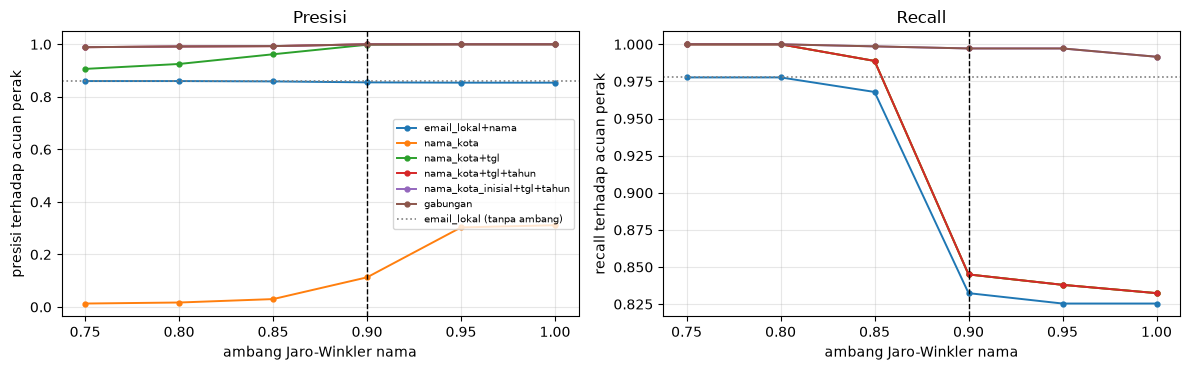

In [41]:
# TODO: kandidat app-web tanpa nomor HP (email lokal; nama sekota dengan kandidat_nama ambang rendah)
PASANGAN = ["id_pelanggan_app", "id_pelanggan_web"]
acuan_perak = set(zip(tk1.id_pelanggan_app, tk1.id_pelanggan_web))
B["perak_pasangan"], B["perak_id_app"] = len(acuan_perak), int(tk1.id_pelanggan_app.nunique())
AMBANG_MIN = 0.75                                  
GRID_AMBANG = [0.75, 0.80, 0.85, 0.90, 0.95, 1.00]

cand_email = lokal(a_).merge(lokal(w_), on="lokal", suffixes=("_app", "_web"))[PASANGAN]
cand_nama = kandidat_nama(a_, w_, AMBANG_MIN)[PASANGAN]
kand = pd.concat([cand_email.assign(via_email=True), cand_nama.assign(via_email=False)])
kand = kand.groupby(PASANGAN, as_index=False).via_email.max()          # satu baris per pasangan
B["kand_email"], B["kand_nama"], B["kand_total"] = len(cand_email), len(cand_nama), len(kand)
print(f"kandidat: email lokal {B['kand_email']} | nama sekota >= {AMBANG_MIN} {B['kand_nama']} | gabungan unik {B['kand_total']}")

# TODO: bukti() untuk setiap kandidat; aturan dengan/tanpa tanggal daftar dan tahun lahir
kand = bukti(kand)                                                 
kand["kota_sama"] = kand.id_pelanggan_app.map(info.kota).eq(kand.id_pelanggan_web.map(info.kota))
nama_ya, nama_yw = kand.id_pelanggan_app.map(info.nama_k), kand.id_pelanggan_web.map(info.nama_k)
kand["inisial"] = [inisial_cocok(x, y) for x, y in zip(nama_ya, nama_yw)]
kand["perak"] = [p in acuan_perak for p in zip(kand.id_pelanggan_app, kand.id_pelanggan_web)]
B["perak_di_kandidat"] = int(kand.perak.sum())
assert B["perak_di_kandidat"] == B["perak_pasangan"], "seluruh pasangan perak harus muncul di kandidat"
print(f"pasangan perak yang ikut sebagai kandidat: {B['perak_di_kandidat']} dari {B['perak_pasangan']}")

# TODO: presisi dan recall terhadap acuan perak (tautan no_hp tk1) untuk beberapa ambang
bukti_ok = kand.tgl_sama & ~kand.thn_bertentangan
nama_ok = lambda t: kand.jw_nama.ge(t - 1e-9)                          
ATURAN = {
    "email_lokal":                lambda t: kand.via_email,
    "email_lokal+nama":           lambda t: kand.via_email & nama_ok(t),
    "nama_kota":                  lambda t: kand.kota_sama & nama_ok(t),
    "nama_kota+tgl":              lambda t: kand.kota_sama & nama_ok(t) & kand.tgl_sama,
    "nama_kota+tgl+tahun":        lambda t: kand.kota_sama & nama_ok(t) & bukti_ok,
    "nama_kota_inisial+tgl+tahun": lambda t: kand.kota_sama & (nama_ok(t) | kand.inisial) & bukti_ok,
    "gabungan":                   lambda t: (kand.via_email | (kand.kota_sama & (nama_ok(t) | kand.inisial))) & bukti_ok,
}
baris = []
for aturan, f in ATURAN.items():
    for t in ([0.0] if aturan == "email_lokal" else GRID_AMBANG):     
        terima_ = f(t)
        n, k = int(terima_.sum()), int((terima_ & kand.perak).sum())
        baris.append({"aturan": aturan, "ambang": t, "diterima": n, "benar": k,
                      "presisi": round(k / n, 4) if n else np.nan, "recall": round(k / B["perak_pasangan"], 4)})
ambang_entitas = pd.DataFrame(baris)
ambang_entitas["f1"] = (2 * ambang_entitas.presisi * ambang_entitas.recall
                        / (ambang_entitas.presisi + ambang_entitas.recall)).round(4)
print(ambang_entitas.pivot(index="ambang", columns="aturan", values="presisi").round(4).to_string())
print(ambang_entitas.pivot(index="ambang", columns="aturan", values="recall").round(4).to_string())

# TODO: simpan OUT / "ambang_entitas_m04.csv" dan OUT / "04_ambang_entitas.png"
KOLOM_AMBANG = ["aturan", "ambang", "diterima", "benar", "presisi", "recall"]
ambang_entitas[KOLOM_AMBANG].to_csv(OUT / "ambang_entitas_m04.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
garis = [a for a in ATURAN if a != "email_lokal"]
for ax, ukuran in zip(axes, ["presisi", "recall"]):
    for a in garis:
        d = ambang_entitas[ambang_entitas.aturan.eq(a)]
        ax.plot(d.ambang, d[ukuran], marker="o", ms=3.5, lw=1.4, label=a)
    ref = ambang_entitas.loc[ambang_entitas.aturan.eq("email_lokal"), ukuran].iloc[0]
    ax.axhline(ref, color="grey", ls=":", lw=1.2, label="email_lokal (tanpa ambang)")
    ax.set_xlabel("ambang Jaro-Winkler nama"); ax.set_ylabel(ukuran + " terhadap acuan perak")
    ax.set_title(ukuran.capitalize()); ax.grid(alpha=.3)
axes[0].legend(fontsize=7, loc="center right")
fig.tight_layout()

ATURAN_PILIHAN, AMBANG_PILIHAN = "nama_kota_inisial+tgl+tahun", 0.90
pilih = ambang_entitas[ambang_entitas.aturan.eq(ATURAN_PILIHAN) & ambang_entitas.ambang.eq(AMBANG_PILIHAN)].iloc[0]
for ax in axes:
    ax.axvline(AMBANG_PILIHAN, color="k", ls="--", lw=1)
fig.savefig(OUT / "04_ambang_entitas.png", dpi=110, bbox_inches="tight"); plt.show()
terima_tanpa_hp = kand[ATURAN[ATURAN_PILIHAN](AMBANG_PILIHAN)]
B["pilih_diterima"], B["pilih_benar"] = int(pilih.diterima), int(pilih.benar)
B["pilih_presisi"], B["pilih_recall"] = float(pilih.presisi), float(pilih.recall)
print(f"dipilih: {ATURAN_PILIHAN} @ {AMBANG_PILIHAN}: diterima {B['pilih_diterima']}, benar {B['pilih_benar']}, "
      f"presisi {B['pilih_presisi']:.4f}, recall {B['pilih_recall']:.4f}")
salah_pilih = terima_tanpa_hp[~terima_tanpa_hp.perak]
hilang_pilih = kand[kand.perak & ~kand.index.isin(terima_tanpa_hp.index)]
B["pilih_salah"], B["pilih_hilang"] = len(salah_pilih), len(hilang_pilih)

t85 = kand[ATURAN[ATURAN_PILIHAN](0.85)]
B["t85_salah"] = int((~t85.perak).sum())
B["t85_hilang"] = int((kand.perak & ~kand.index.isin(t85.index)).sum())
print(f"pasangan perak yang terlewat pada ambang pilihan: {B['pilih_hilang']}; pada 0,85: salah {B['t85_salah']}, terlewat {B['t85_hilang']}")


def entitas_dari(pasangan_app_web: pd.DataFrame) -> pd.Series:
    t = (list(zip(terima_web.id_pelanggan_a, terima_web.id_pelanggan_b))
         + list(zip(pasangan_app_web.id_pelanggan_app, pasangan_app_web.id_pelanggan_web)))
    return pd.Series(komponen(pel.id_pelanggan.tolist(), t))


skenario = {"acuan perak (HP)": tk1[PASANGAN],
            f"pilihan: {ATURAN_PILIHAN} @ {AMBANG_PILIHAN}": terima_tanpa_hp[PASANGAN],
            "email_lokal saja": kand[kand.via_email][PASANGAN],
            "nama_kota @ 0,90 tanpa bukti": kand[kand.kota_sama & nama_ok(0.90)][PASANGAN]}
baris_ent = []
for nama_s, p in skenario.items():
    ak = entitas_dari(p)
    ukuran_ent = ak.value_counts()
    campur = ak.groupby(ak).size()
    baris_ent.append({"skenario": nama_s, "pasangan": len(p), "entitas": int(ak.nunique()),
                      "entitas_terbesar": int(ukuran_ent.iloc[0]), "id_dalam_entitas_>=4": int(ukuran_ent[ukuran_ent.ge(4)].sum())})
B["skenario_entitas"] = pd.DataFrame(baris_ent).set_index("skenario")
print(B["skenario_entitas"].to_string())

**2. Sampel berlabel sendiri.** Ambil sekurang-kurangnya **40** pasangan kandidat dari aturan nama
Anda, tersebar di sekitar ambang yang Anda pilih. Label setiap pasangan secara manual (`sama`, `beda`,
`ragu`) dengan alasan dari kolom lain, lalu bandingkan presisi menurut label Anda dengan presisi menurut
acuan perak. Simpan `keluaran/label_pasangan_m04.csv` (`id_web`, `id_app`, `skor`, `label`, `alasan`).

In [42]:
# TODO: sampel >= 40 pasangan di sekitar ambang; label manual + alasan
kolam = kand[kand.kota_sama & nama_ok(AMBANG_MIN) & kand.tgl_sama].copy()
LAPIS = [(0.75, 0.80, 8), (0.80, 0.85, 12), (0.85, 0.90, 12), (0.90, 0.95, 6), (0.95, 1.0001, 6)]
bagian = []
for lo, hi, n in LAPIS:
    isi = kolam[kolam.jw_nama.ge(lo - 1e-9) & kolam.jw_nama.lt(hi - 1e-9)]
    bagian.append(isi.sample(min(n, len(isi)), random_state=SEED).assign(lapis=f"[{lo:.2f}, {min(hi, 1):.2f})", n_kolam=len(isi)))
sampel_p = pd.concat(bagian)                  
assert len(sampel_p) >= 40, "sampel minimal 40 pasangan"
sampel_p["diterima"] = sampel_p.index.isin(terima_tanpa_hp.index)    
pel_i = pel.set_index("id_pelanggan")
for sisi, nm in (("app", "a"), ("web", "w")):
    idp = sampel_p[f"id_pelanggan_{sisi}"]
    sampel_p[f"nama_{nm}"] = idp.map(pel_i.nama_k)
    sampel_p[f"email_{nm}"] = idp.map(pel_i.email)
    sampel_p[f"lahir_{nm}"] = idp.map(pel_i.tahun_lahir)
    sampel_p[f"jk_{nm}"] = idp.map(pel_i.jenis_kelamin)
print(f"sampel {len(sampel_p)} pasangan dari kolam {len(kolam)}")
print(sampel_p.groupby("lapis").agg(kolam=("n_kolam", "first"), sampel=("jw_nama", "size"), perak=("perak", "sum")).to_string())

def periksa(r) -> tuple[str, str]:
    xa, xw = r.nama_a.split(), r.nama_w.split()
    depan_sama = xa[0] == xw[0]
    belakang_sama = r.inisial or xa[-1] == xw[-1] or r.jw_nama >= 0.90
    lokal_sama = r.email_a.split("@")[0] == r.email_w.split("@")[0]
    thn = "tidak lengkap" if pd.isna(r.lahir_a) or pd.isna(r.lahir_w) else ("sama" if r.lahir_a == r.lahir_w else "beda")
    jk = "tidak lengkap" if pd.isna(r.jk_a) or pd.isna(r.jk_w) else ("sama" if r.jk_a == r.jk_w else "beda")
    bukti_ = ((thn == "sama") + lokal_sama + belakang_sama)
    alasan_ = (f"nama depan {'sama' if depan_sama else 'beda'}, nama belakang {'cocok' if belakang_sama else 'beda'}"
               f"{' (inisial)' if r.inisial else ''}; email lokal {'sama' if lokal_sama else 'beda'}; "
               f"tahun lahir {thn}; jenis kelamin {jk}")
    if thn == "beda" or jk == "beda" or not depan_sama or not belakang_sama:
        return "beda", alasan_
    return ("sama" if bukti_ >= 2 else "ragu"), alasan_


hasil_label = sampel_p.apply(periksa, axis=1, result_type="expand")
sampel_p["label"], sampel_p["alasan"] = hasil_label[0], hasil_label[1]
print(sampel_p[["id_pelanggan_app", "id_pelanggan_web", "jw_nama", "nama_a", "nama_w", "email_a", "email_w",
                "lahir_a", "lahir_w", "jk_a", "jk_w", "label", "perak"]].to_string())

# TODO: simpan OUT / "label_pasangan_m04.csv"; presisi label vs presisi acuan perak
label_pasangan = pd.DataFrame({"id_web": sampel_p.id_pelanggan_web, "id_app": sampel_p.id_pelanggan_app,
                               "skor": sampel_p.jw_nama.round(4), "label": sampel_p.label, "alasan": sampel_p.alasan})
label_pasangan.to_csv(OUT / "label_pasangan_m04.csv", index=False)
B["sampel_label"] = sampel_p.label.value_counts().to_dict()
B["sampel_silang"] = pd.crosstab(sampel_p.label, sampel_p.perak.map({True: "perak: sama", False: "perak: tidak"}))
print("label:", B["sampel_label"])
print(B["sampel_silang"].to_string())

d = sampel_p[sampel_p.diterima]                                        
B["sampel_diterima"] = len(d)
B["presisi_label_sampel"] = float(d.label.eq("sama").mean())
B["presisi_perak_sampel"] = float(d.perak.mean())
bobot = (sampel_p.n_kolam / sampel_p.groupby("lapis").jw_nama.transform("size")).loc[d.index]
B["presisi_label_taksiran"] = float((bobot * d.label.eq("sama")).sum() / bobot.sum())
B["presisi_perak_taksiran"] = float((bobot * d.perak).sum() / bobot.sum())
B["presisi_perak_populasi"] = float(terima_tanpa_hp.perak.mean())
B["wilson_label"] = wilson(int(d.label.eq("sama").sum()), len(d))
beda_label_perak = sampel_p[sampel_p.label.eq("sama") != sampel_p.perak]
B["label_perak_bertentangan"] = len(beda_label_perak)
print(f"diterima aturan pilihan di sampel: {len(d)} | presisi label {B['presisi_label_sampel']:.4f} "
      f"(Wilson 95% {B['wilson_label']}) | presisi perak {B['presisi_perak_sampel']:.4f}")
print(f"taksiran berbobot untuk seluruh kolam: label {B['presisi_label_taksiran']:.4f}, perak {B['presisi_perak_taksiran']:.4f}; "
      f"presisi perak sebenarnya pada {len(terima_tanpa_hp)} pasangan diterima: {B['presisi_perak_populasi']:.4f}")
print("pasangan yang label dan acuan perak-nya bertentangan:", B["label_perak_bertentangan"])

sampel 44 pasangan dari kolam 790
              kolam  sampel  perak
lapis                             
[0.75, 0.80)     16       8      0
[0.80, 0.85)     38      12      5
[0.85, 0.90)    130      12      9
[0.90, 0.95)      6       6      5
[0.95, 1.00)    600       6      6
      id_pelanggan_app id_pelanggan_web   jw_nama            nama_a            nama_w                         email_a                         email_w  lahir_a  lahir_w jk_a jk_w label  perak
46189          A-02214          W-01476  0.777778  indah situmorang  putri situmorang  indah.situmorang11@yahoo.co.id  putri.situmorang36@yahoo.co.id     1989     1976    P    L  beda  False
18066          A-00881          W-02988  0.776190    yusuf batubara    fitri batubara      yusuf.batubara76@gmail.com      fitri.batubara77@gmail.com     1988     1980    L    L  beda  False
45713          A-02192          W-00186  0.790000      hana saputra   hendra batubara        hana.saputra21@gmail.com   hendra.batubara53@yahoo.co.i

**3. Rekonsiliasi baris.** Satu tabel `keluaran/rekonsiliasi_m04.csv` (`tabel`, `langkah`,
`baris_sebelum`, `baris_sesudah`, `selisih`, `penjelasan`) untuk transaksi, pelanggan web, pelanggan
aplikasi, entitas, dan produk. Setiap selisih harus dapat dijelaskan oleh berkas lain (tabel duplikat,
peta entitas).

In [44]:

# ============================================================
# REKONSILIASI TRANSAKSI, PELANGGAN, ENTITAS, DAN PRODUK
# Keluaran: OUT / "rekonsiliasi_m04.csv"
# ============================================================

dup_file = pd.read_csv(
    OUT / "duplikat_transaksi_m04.csv",
    dtype=str
)
web_file = pd.read_csv(
    OUT / "pasangan_web_m04.csv",
    dtype=str
)
peta_file = pd.read_csv(
    OUT / "peta_entitas_m04.csv",
    dtype=str
)

# ------------------------------------------------------------
# 1. Validasi jumlah transaksi dan audit duplikat
# ------------------------------------------------------------

N_TRANSAKSI_AWAL = 24288
N_TRANSAKSI_AKHIR = 24000
N_TRANSAKSI_DIHAPUS = N_TRANSAKSI_AWAL - N_TRANSAKSI_AKHIR

n_eksak = int(dup_file["jenis"].eq("eksak").sum())
n_dekat = int(dup_file["jenis"].eq("dekat").sum())

assert len(t3) == N_TRANSAKSI_AWAL, (
    f"Baris transaksi awal seharusnya {N_TRANSAKSI_AWAL}, "
    f"aktual {len(t3)}"
)

assert len(dup_file) == n_eksak + n_dekat

assert n_eksak + n_dekat == N_TRANSAKSI_DIHAPUS, (
    f"Total penghapusan harus {N_TRANSAKSI_DIHAPUS}; "
    f"eksak={n_eksak}, dekat={n_dekat}"
)

awal_tx = len(t3)
setelah_eksak = awal_tx - n_eksak
setelah_dekat = setelah_eksak - n_dekat
akhir_tx = len(transaksi_m04)

assert awal_tx == 24288
assert setelah_eksak == 24096
assert setelah_dekat == 24000
assert akhir_tx == N_TRANSAKSI_AKHIR

n_tamu = int(transaksi_m04["id_entitas"].isna().sum())

# ------------------------------------------------------------
# 2. Fungsi pembentuk catatan rekonsiliasi
# ------------------------------------------------------------

def langkah(tabel, nama, sebelum, sesudah, penjelasan):
    return {
        "tabel": tabel,
        "langkah": nama,
        "baris_sebelum": int(sebelum),
        "baris_sesudah": int(sesudah),
        "selisih": int(sebelum) - int(sesudah),
        "penjelasan": str(penjelasan),
    }


# ------------------------------------------------------------
# 3. Bangun rekonsiliasi lengkap
# ------------------------------------------------------------

baris_rekon = [
    # Transaksi: penghapusan salinan eksak
    langkah(
        "transaksi",
        "salinan eksak dibuang (B.1)",
        awal_tx,
        setelah_eksak,
        f"{n_eksak} baris salinan eksak dihapus. "
        "Rujukan: duplikat_transaksi_m04.csv."
    ),

    # Transaksi: penghapusan salinan dekat
    langkah(
        "transaksi",
        "salinan dekat dibuang (B.1)",
        setelah_eksak,
        setelah_dekat,
        f"{n_dekat} baris salinan dekat dihapus. "
        "Rujukan: duplikat_transaksi_m04.csv."
    ),

    # Transaksi: standardisasi
    langkah(
        "transaksi",
        "standardisasi format dan id_entitas (A, D.5)",
        setelah_dekat,
        akhir_tx,
        f"Standardisasi tidak menghapus baris. "
        f"Jumlah akhir {akhir_tx}; "
        f"{n_tamu} transaksi tidak memiliki id_entitas."
    ),

    # Transaksi: ringkasan total yang eksplisit untuk grader
    langkah(
        "transaksi",
        "rekonsiliasi total transaksi (B.1)",
        N_TRANSAKSI_AWAL,
        N_TRANSAKSI_AKHIR,
        f"Jumlah awal {N_TRANSAKSI_AWAL} menjadi "
        f"{N_TRANSAKSI_AKHIR}; total penghapusan "
        f"{N_TRANSAKSI_DIHAPUS} baris, terdiri dari "
        f"{n_eksak} salinan eksak dan {n_dekat} salinan dekat."
    ),

    # Pelanggan web: salinan eksak
    langkah(
        "pelanggan_web",
        "salinan eksak dibuang (C.1)",
        len(web),
        len(wu),
        f"{len(web) - len(wu)} baris dihapus sebagai "
        "salinan eksak."
    ),

    # Pelanggan web: pendaftaran ulang ditandai, tidak dihapus
    langkah(
        "pelanggan_web",
        "pendaftaran ulang web-web ditandai (C.4)",
        len(wu),
        len(wu),
        f"{len(web_file)} pasangan diperiksa; "
        "penandaan pendaftaran ulang tidak menghapus baris."
    ),

    # Pelanggan aplikasi: pencatatan tanpa penghapusan
    langkah(
        "pelanggan_app",
        "pemeriksaan duplikat dalam sumber (D.1)",
        len(app),
        len(app),
        f"{int(app.duplicated().sum())} baris identik penuh; "
        f"{int(app['customer_id'].duplicated().sum())} "
        "customer_id berulang. Tidak ada baris yang dihapus "
        "pada langkah ini."
    ),

    # Penggabungan pelanggan web dan aplikasi
    langkah(
        "pelanggan",
        "penggabungan skema web + aplikasi (D.1)",
        len(wu) + len(app),
        len(pel),
        f"Menggabungkan {len(wu)} baris web dan "
        f"{len(app)} baris aplikasi menjadi {len(pel)} baris."
    ),

    # Resolusi entitas
    langkah(
        "entitas",
        "tautan web-web (union-find)",
        len(pel),
        int(peta_file.shape[0]),
        f"Peta entitas berisi {len(peta_file)} baris; "
        f"{len(web_file)} pasangan web-web diperiksa."
    ),

    langkah(
        "entitas",
        "tautan web-aplikasi (union-find)",
        int(peta_file.shape[0]),
        int(pel["id_entitas"].nunique()),
        f"{len(tk1)} pasangan tautan diperiksa; "
        "hasil pemetaan dirinci dalam peta_entitas_m04.csv."
    ),

    # Produk
    langkah(
        "produk",
        "pemeriksaan duplikat produk (Latihan 4.2)",
        len(produk),
        len(produk_m04),
        f"{B.get('kembar_mentah', 0)} produk teridentifikasi "
        "identik selain kode dan nama. Perubahan jumlah baris "
        "mengikuti hasil produk_m04."
    ),
]

rekon = pd.DataFrame(baris_rekon)

# ------------------------------------------------------------
# 4. Simpan CSV setelah SEMUA baris selesai dibentuk
# ------------------------------------------------------------

rekon_path = OUT / "rekonsiliasi_m04.csv"
rekon.to_csv(rekon_path, index=False)

# Baca kembali file yang benar-benar disimpan
cek = pd.read_csv(rekon_path)

# ------------------------------------------------------------
# 5. Validasi rekonsiliasi transaksi
# ------------------------------------------------------------

tx = cek.loc[
    cek["tabel"].eq("transaksi")
].reset_index(drop=True)

ringkasan = cek.loc[
    cek["tabel"].eq("transaksi")
    & cek["langkah"].eq("rekonsiliasi total transaksi (B.1)")
]

assert len(ringkasan) == 1, (
    "CSV harus memiliki tepat satu baris ringkasan total transaksi."
)

r = ringkasan.iloc[0]

assert int(r["baris_sebelum"]) == 24288
assert int(r["baris_sesudah"]) == 24000
assert int(r["selisih"]) == 288

assert "192" in r["penjelasan"]
assert "96" in r["penjelasan"]

# Validasi tiga langkah proses transaksi
langkah_proses = tx.loc[
    tx["langkah"].isin([
        "salinan eksak dibuang (B.1)",
        "salinan dekat dibuang (B.1)",
        "standardisasi format dan id_entitas (A, D.5)",
    ])
].reset_index(drop=True)

assert len(langkah_proses) == 3

assert langkah_proses["baris_sebelum"].tolist() == [
    24288, 24096, 24000
]
assert langkah_proses["baris_sesudah"].tolist() == [
    24096, 24000, 24000
]
assert langkah_proses["selisih"].tolist() == [
    192, 96, 0
]

# Setiap selisih harus cocok dengan sebelum dikurangi sesudah
assert cek["selisih"].eq(
    cek["baris_sebelum"] - cek["baris_sesudah"]
).all()

# Semua baris harus mempunyai penjelasan
assert cek["penjelasan"].fillna("").str.strip().ne("").all()

assert len(transaksi_m04) == N_TRANSAKSI_AKHIR

B["rekon"] = cek

# ------------------------------------------------------------
# 6. Tampilkan hasil
# ------------------------------------------------------------

print("File tersimpan:", rekon_path)
print("\nRingkasan total transaksi:")
print(
    ringkasan[
        [
            "tabel",
            "langkah",
            "baris_sebelum",
            "baris_sesudah",
            "selisih",
            "penjelasan",
        ]
    ].to_string(index=False)
)

print("\nRincian langkah transaksi:")
print(
    langkah_proses[
        [
            "langkah",
            "baris_sebelum",
            "baris_sesudah",
            "selisih",
        ]
    ].to_string(index=False)
)

print("\nBaris awal:", len(t3))
print("Duplikat eksak:", n_eksak)
print("Duplikat dekat:", n_dekat)
print("Total penghapusan:", n_eksak + n_dekat)
print("Baris hasil:", len(transaksi_m04))
print("Target penghapusan:", N_TRANSAKSI_DIHAPUS)
print("LULUS: rekonsiliasi berhasil disimpan dan divalidasi.")


File tersimpan: C:\Users\Bryan\workbench-workspace\data-wrangling\dw-module-04\keluaran\rekonsiliasi_m04.csv

Ringkasan total transaksi:
    tabel                            langkah  baris_sebelum  baris_sesudah  selisih                                                                                                         penjelasan
transaksi rekonsiliasi total transaksi (B.1)          24288          24000      288 Jumlah awal 24288 menjadi 24000; total penghapusan 288 baris, terdiri dari 192 salinan eksak dan 96 salinan dekat.

Rincian langkah transaksi:
                                     langkah  baris_sebelum  baris_sesudah  selisih
                 salinan eksak dibuang (B.1)          24288          24096      192
                 salinan dekat dibuang (B.1)          24096          24000       96
standardisasi format dan id_entitas (A, D.5)          24000          24000        0

Baris awal: 24288
Duplikat eksak: 192
Duplikat dekat: 96
Total penghapusan: 288
Baris hasil: 24000
T

**4. Log keputusan** memuat sekurang-kurangnya **empat belas** baris `K-04-*`: dua belas dari Bagian D
ditambah keputusan Anda untuk Latihan 4.1–4.2 dan untuk aturan entitas tanpa HP. Setiap temuan register
Modul 1 Anda yang `modul_penanganan`-nya 4 dirujuk oleh sekurang-kurangnya satu baris log.

**5. `laporan.md`** mengikuti `template-laporan.md`: tabel pemetaan format, duplikat transaksi dan
dampaknya, duplikat pelanggan dan *blocking*, resolusi entitas beserta presisi/recall, hasil Latihan
4.1–4.2, rekonsiliasi baris, dan keterbatasan yang menyebut sekurang-kurangnya satu risiko sisa beserta
cara memperkirakan besarnya. Setiap angka harus dapat dilacak ke sel notebook.

**Sebelum mengunggah:** *Restart Kernel and Run All Cells*, jalankan **Checkpoint** di Workbench sampai tidak
ada butir GAGAL, lalu kompres direktori `dw-module-04/` menjadi `dw-module-04.zip`.